In [84]:
import torch
import torch.nn as nn
import torch.optim as optim

import numpy as np
import matplotlib.pyplot as plt

from torch.utils.data import DataLoader
from torchvision import datasets, transforms

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Device: cuda
GPU: NVIDIA GeForce RTX 4060 Laptop GPU


In [85]:
import pickle

with open("vehicle_split.pkl","rb") as f:
    data =pickle.load(f)

print(type(data))

<class 'dict'>


In [86]:
print(data.keys())

dict_keys(['X_train', 'X_val', 'y_train', 'y_val'])


In [87]:
X_train = data["X_train"]
X_val = data["X_val"]
y_train = data["y_train"]
y_val = data["y_val"]
print("Train samples:", len(X_train))
print("Validation samples:", len(X_val))

print("First image path:",X_train[0])
print("First label:",y_train[0])

Train samples: 1537
Validation samples: 385
First image path: C:\Users\ASUS\Desktop\مکتب شریف\مکتب 145\پروژه دوم\data\train - merge - clean\kamyunet\215916570.jpg
First label: 3


In [88]:
import sys
from pathlib import Path

sys.path.append(str(Path.cwd().parent))

print("Project path:", Path.cwd().parent)

Project path: c:\Users\ASUS\Desktop\مکتب شریف\مکتب 145\پروژه دوم


In [89]:
from src.data_loader import create_dataloaders

In [90]:
train_loader ,val_loader = create_dataloaders(
    X_train,
    X_val,
    y_train,
    y_val,
    batch_size=32
)

In [91]:
print("Train batches:", len(train_loader))
print("Validation batches:", len(val_loader))

images, labels = next(iter(train_loader))

print("Images shape:", images.shape)
print("Labels shape:", labels.shape)
print("Image dtype:", images.dtype)
print("Label dtype:", labels.dtype)

Train batches: 49
Validation batches: 13
Images shape: torch.Size([32, 3, 224, 224])
Labels shape: torch.Size([32])
Image dtype: torch.float32
Label dtype: torch.int64


# CNN baseline 

In [92]:
# CNN baseline 

class SimpleCNN(nn.Module):
    def __init__(self,num_classes=8):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(3,32,kernel_size=3,padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32,64,kernel_size=3,padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64*56*56,128),
            nn.ReLU(),
            nn.Linear(128,num_classes)
        )


    def forward(self,x) : 
        x = self.features(x)
        x = self.classifier(x)
        return x

In [93]:
model = SimpleCNN(num_classes = 8).to(device)
print(model)

SimpleCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=200704, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=8, bias=True)
  )
)


In [94]:
images , labels = next(iter(train_loader))

images = images.to(device)

outputs = model(images)

print("images : ", images.shape)
print("outputs", outputs.shape)

images :  torch.Size([32, 3, 224, 224])
outputs torch.Size([32, 8])


In [95]:
criterion = nn.CrossEntropyLoss()
print(criterion)

CrossEntropyLoss()


In [96]:
labels = labels.to(device)
loss = criterion(outputs,labels)
print("Loss :",loss.item() )

Loss : 2.0684072971343994


In [97]:
optimizer = optim.Adam(
    model.parameters(),
    lr = 0.001
)
print(optimizer)

Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0
)


In [98]:
print("Outputs shape:", outputs.shape)
print("Labels shape:", labels.shape)
print("Labels dtype:", labels.dtype)

Outputs shape: torch.Size([32, 8])
Labels shape: torch.Size([32])
Labels dtype: torch.int64


In [99]:
images, labels = next(iter(train_loader))

print("Images shape:", images.shape)
print("Images dtype:", images.dtype)

print("Labels shape:", labels.shape)
print("Labels dtype:", labels.dtype)

Images shape: torch.Size([32, 3, 224, 224])
Images dtype: torch.float32
Labels shape: torch.Size([32])
Labels dtype: torch.int64


In [100]:
images = images.to(device)
labels = labels.to(device)

outputs = model(images)

loss = criterion(outputs, labels)

optimizer.zero_grad()

loss.backward()

optimizer.step()

print("Training loss:", loss.item())

Training loss: 2.0822672843933105


In [101]:
images,labels = next(iter(train_loader))

images = images.to(device)
labels = labels.to(device)

optimizer.zero_grad()

outputs = model(images)

loss = criterion(outputs,labels)

loss.backward()

optimizer.step()

print("training loss : ",loss.item())

training loss :  30.90467643737793


In [102]:
num_epochs = 5
for epoch in range(num_epochs):
    model.train()

    running_loss = 0

    for images,labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)

        loss = criterion(outputs,labels)

        loss.backward()

        optimizer.step()

        running_loss += loss.item()

    epoch_loss = running_loss/len(train_loader)

    print(
        f"Epoch : [{epoch+1}/{num_epochs}]"
        f"Train loss : {epoch_loss}"
    )

Epoch : [1/5]Train loss : 2.2560189086563733
Epoch : [2/5]Train loss : 1.5771357526584548
Epoch : [3/5]Train loss : 1.168440535360453
Epoch : [4/5]Train loss : 1.016612206186567
Epoch : [5/5]Train loss : 0.6961735450491613


In [103]:
model.eval()
val_loss = 0

with torch.no_grad():
    for images,labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)
    
            optimizer.zero_grad()
    
            outputs = model(images)
    
            loss = criterion(outputs,labels)
    
            val_loss += loss.item()
    
val_loss = val_loss/len(val_loader)
    
print("validation loss:",val_loss
)

validation loss: 0.9450129843675174


In [104]:
model = SimpleCNN(num_classes = 8).to(device)
criterion = nn.CrossEntropyLoss()


optimizer = optim.Adam(
model.parameters(),
lr = 0.001

)



In [105]:
num_epochs = 10
best_val_accuracy_baseline = 0.0

for epoch in range(num_epochs):

    # =====================
    # Training
    # =====================
    model.train()

    running_train_loss = 0.0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)

        loss = criterion(outputs, labels)

        loss.backward()

        optimizer.step()

        running_train_loss += loss.item()

    train_loss = running_train_loss / len(train_loader)


    # =====================
    # Validation
    # =====================
    model.eval()

    running_val_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            loss = criterion(outputs, labels)

            running_val_loss += loss.item()

            predictions = outputs.argmax(dim=1)

            total += labels.size(0)
            correct += (predictions == labels).sum().item()

    val_loss = running_val_loss / len(val_loader)
    val_accuracy = 100 * correct / total


    # =====================
    # Results
    # =====================
    print(
        f"Epoch [{epoch+1}/{num_epochs}] "
        f"Train Loss: {train_loss:} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Accuracy: {val_accuracy:.2f}%"
    )
    if val_accuracy > best_val_accuracy_baseline:

            best_val_accuracy_baseline = val_accuracy

            torch.save(
                model.state_dict(),
                "../models/simplecnn_baseline_best.pth"
            )

            print(
                f"Best checkpoint saved: "
                f"{best_val_accuracy_baseline:.2f}%"
            )

print(
f"\nBest CNN Baseline Validation Accuracy: "
f"{best_val_accuracy_baseline:.2f}%"
)


Epoch [1/10] Train Loss: 2.3197832642769325 | Val Loss: 1.5731 | Val Accuracy: 42.60%
Best checkpoint saved: 42.60%
Epoch [2/10] Train Loss: 1.3870578079807514 | Val Loss: 1.3706 | Val Accuracy: 48.83%
Best checkpoint saved: 48.83%
Epoch [3/10] Train Loss: 0.987022476080729 | Val Loss: 0.9021 | Val Accuracy: 67.01%
Best checkpoint saved: 67.01%
Epoch [4/10] Train Loss: 0.4905284828677469 | Val Loss: 0.7763 | Val Accuracy: 72.73%
Best checkpoint saved: 72.73%
Epoch [5/10] Train Loss: 0.2826340570285612 | Val Loss: 0.7666 | Val Accuracy: 72.47%
Epoch [6/10] Train Loss: 0.12785763544391612 | Val Loss: 0.7628 | Val Accuracy: 76.36%
Best checkpoint saved: 76.36%
Epoch [7/10] Train Loss: 0.052613043950927654 | Val Loss: 0.7033 | Val Accuracy: 78.44%
Best checkpoint saved: 78.44%
Epoch [8/10] Train Loss: 0.013286648047327692 | Val Loss: 0.7586 | Val Accuracy: 77.40%
Epoch [9/10] Train Loss: 0.006263291515477583 | Val Loss: 0.7452 | Val Accuracy: 79.22%
Best checkpoint saved: 79.22%
Epoch [10/

# SimpleCNNDropout

In [106]:
class SimpleCNNDropout(nn.Module):
    def __init__(self,num_classes=8,dropout_p=0.0):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(3,32,kernel_size=3,padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32,64,kernel_size=3,padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64*56*56,128),
            nn.ReLU(),
            nn.Dropout(p=dropout_p),
            nn.Linear(128,num_classes)
        )


    def forward(self,x) : 
        x = self.features(x)
        x = self.classifier(x)
        return x

In [107]:
model_p0 = SimpleCNNDropout(
    num_classes=8,
    dropout_p=0
)

model_p0 = model_p0.to(device)
print(model_p0)

SimpleCNNDropout(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=200704, out_features=128, bias=True)
    (2): ReLU()
    (3): Dropout(p=0, inplace=False)
    (4): Linear(in_features=128, out_features=8, bias=True)
  )
)


In [108]:
import random

seed = 42

random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(seed)



model_p0 = SimpleCNNDropout(
    num_classes=8,
    dropout_p=0.0
).to(device)

criterion_p0 = nn.CrossEntropyLoss()

optimizer_p0 = optim.Adam(
    model_p0.parameters(),
    lr=0.001
)

num_epochs = 10

best_val_accuracy_p0 = 0.0

train_losses_p0 = []
val_losses_p0 = []
val_accuracies_p0 = []


for epoch in range(num_epochs):

    # =====================
    # Training
    # =====================
    model_p0.train()

    running_train_loss = 0.0
    train_total = 0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer_p0.zero_grad()

        outputs = model_p0(images)

        loss = criterion_p0(outputs, labels)

        loss.backward()
        optimizer_p0.step()

        running_train_loss += loss.item() * images.size(0)
        train_total += images.size(0)

    train_loss = running_train_loss / train_total


    # =====================
    # Validation
    # =====================
    model_p0.eval()

    running_val_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model_p0(images)

            loss = criterion_p0(outputs, labels)

            running_val_loss += loss.item() * images.size(0)

            predictions = outputs.argmax(dim=1)

            correct += (predictions == labels).sum().item()
            total += labels.size(0)

    val_loss = running_val_loss / total
    val_accuracy = 100 * correct / total


    # Save history
    train_losses_p0.append(train_loss)
    val_losses_p0.append(val_loss)
    val_accuracies_p0.append(val_accuracy)


    print(
        f"Epoch [{epoch+1}/{num_epochs}] "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Accuracy: {val_accuracy:.2f}%"
    )


    # Save best model
    if val_accuracy > best_val_accuracy_p0:

        best_val_accuracy_p0 = val_accuracy

        torch.save(
            model_p0.state_dict(),
            "../models/simplecnn_dropout_p0_best.pth"
        )

        print(
            f"Best checkpoint saved: "
            f"{best_val_accuracy_p0:.2f}%"
        )


print(
    f"\nBest Validation Accuracy (p=0): "
    f"{best_val_accuracy_p0:.2f}%"
)

Epoch [1/10] Train Loss: 1.9582 | Val Loss: 1.5571 | Val Accuracy: 35.58%
Best checkpoint saved: 35.58%
Epoch [2/10] Train Loss: 1.2430 | Val Loss: 1.3711 | Val Accuracy: 50.13%
Best checkpoint saved: 50.13%
Epoch [3/10] Train Loss: 0.8446 | Val Loss: 1.0374 | Val Accuracy: 63.12%
Best checkpoint saved: 63.12%
Epoch [4/10] Train Loss: 0.5697 | Val Loss: 1.0334 | Val Accuracy: 66.49%
Best checkpoint saved: 66.49%
Epoch [5/10] Train Loss: 0.5345 | Val Loss: 0.9757 | Val Accuracy: 69.35%
Best checkpoint saved: 69.35%
Epoch [6/10] Train Loss: 0.3214 | Val Loss: 0.9191 | Val Accuracy: 73.25%
Best checkpoint saved: 73.25%
Epoch [7/10] Train Loss: 0.2337 | Val Loss: 0.9691 | Val Accuracy: 73.25%
Epoch [8/10] Train Loss: 0.1540 | Val Loss: 0.8620 | Val Accuracy: 76.88%
Best checkpoint saved: 76.88%
Epoch [9/10] Train Loss: 0.0617 | Val Loss: 1.0725 | Val Accuracy: 72.47%
Epoch [10/10] Train Loss: 0.1210 | Val Loss: 1.0732 | Val Accuracy: 71.69%

Best Validation Accuracy (p=0): 76.88%


In [109]:
import random

seed = 42

random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(seed)


# ساخت دوباره مدل بعد از تعیین seed
model_p3 = SimpleCNNDropout(
    num_classes=8,
    dropout_p=0.3
).to(device)

criterion_p3 = nn.CrossEntropyLoss()

optimizer_p3 = optim.Adam(
    model_p3.parameters(),
    lr=0.001
)

num_epochs = 10

best_val_accuracy_p3 = 0.0

train_losses_p3 = []
val_losses_p3 = []
val_accuracies_p3 = []


for epoch in range(num_epochs):

    # =====================
    # Training
    # =====================
    model_p3.train()

    running_train_loss = 0.0
    train_total = 0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer_p3.zero_grad()

        outputs = model_p3(images)

        loss = criterion_p3(outputs, labels)

        loss.backward()
        optimizer_p3.step()

        running_train_loss += loss.item() * images.size(0)
        train_total += images.size(0)

    train_loss = running_train_loss / train_total


    # =====================
    # Validation
    # =====================
    model_p3.eval()

    running_val_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model_p3(images)

            loss = criterion_p3(outputs, labels)

            running_val_loss += loss.item() * images.size(0)

            predictions = outputs.argmax(dim=1)

            correct += (predictions == labels).sum().item()
            total += labels.size(0)

    val_loss = running_val_loss / total
    val_accuracy = 100 * correct / total


    # Save history
    train_losses_p3.append(train_loss)
    val_losses_p3.append(val_loss)
    val_accuracies_p3.append(val_accuracy)


    print(
        f"Epoch [{epoch+1}/{num_epochs}] "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Accuracy: {val_accuracy:.2f}%"
    )


    # Save best model
    if val_accuracy > best_val_accuracy_p3:

        best_val_accuracy_p3 = val_accuracy

        torch.save(
            model_p3.state_dict(),
            "../models/simplecnn_dropout_p3_best.pth"
        )

        print(
            f"Best checkpoint saved: "
            f"{best_val_accuracy_p3:.2f}%"
        )


print(
    f"\nBest Validation Accuracy (p=0.3): "
    f"{best_val_accuracy_p3:.2f}%"
)

Epoch [1/10] Train Loss: 2.1239 | Val Loss: 1.6189 | Val Accuracy: 35.58%
Best checkpoint saved: 35.58%
Epoch [2/10] Train Loss: 1.4121 | Val Loss: 1.1816 | Val Accuracy: 60.26%
Best checkpoint saved: 60.26%
Epoch [3/10] Train Loss: 1.0426 | Val Loss: 0.9779 | Val Accuracy: 64.68%
Best checkpoint saved: 64.68%
Epoch [4/10] Train Loss: 0.8181 | Val Loss: 0.9876 | Val Accuracy: 67.53%
Best checkpoint saved: 67.53%
Epoch [5/10] Train Loss: 0.6692 | Val Loss: 0.9060 | Val Accuracy: 68.05%
Best checkpoint saved: 68.05%
Epoch [6/10] Train Loss: 0.5383 | Val Loss: 0.7734 | Val Accuracy: 73.51%
Best checkpoint saved: 73.51%
Epoch [7/10] Train Loss: 0.4224 | Val Loss: 0.7952 | Val Accuracy: 72.73%
Epoch [8/10] Train Loss: 0.3290 | Val Loss: 0.7112 | Val Accuracy: 76.62%
Best checkpoint saved: 76.62%
Epoch [9/10] Train Loss: 0.2533 | Val Loss: 0.8541 | Val Accuracy: 72.21%
Epoch [10/10] Train Loss: 0.3152 | Val Loss: 0.8383 | Val Accuracy: 72.73%

Best Validation Accuracy (p=0.3): 76.62%


In [110]:
import random

seed = 42

random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(seed)


# ساخت دوباره مدل بعد از تعیین seed
model_p5 = SimpleCNNDropout(
    num_classes=8,
    dropout_p=0.5
).to(device)

criterion_p5 = nn.CrossEntropyLoss()

optimizer_p5 = optim.Adam(
    model_p5.parameters(),
    lr=0.001
)

num_epochs = 10

best_val_accuracy_p5 = 0.0

train_losses_p5 = []
val_losses_p5 = []
val_accuracies_p5 = []


for epoch in range(num_epochs):

    # =====================
    # Training
    # =====================
    model_p5.train()

    running_train_loss = 0.0
    train_total = 0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer_p5.zero_grad()

        outputs = model_p5(images)

        loss = criterion_p5(outputs, labels)

        loss.backward()
        optimizer_p5.step()

        running_train_loss += loss.item() * images.size(0)
        train_total += images.size(0)

    train_loss = running_train_loss / train_total


    # =====================
    # Validation
    # =====================
    model_p5.eval()

    running_val_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model_p5(images)

            loss = criterion_p5(outputs, labels)

            running_val_loss += loss.item() * images.size(0)

            predictions = outputs.argmax(dim=1)

            correct += (predictions == labels).sum().item()
            total += labels.size(0)

    val_loss = running_val_loss / total
    val_accuracy = 100 * correct / total


    # Save history
    train_losses_p5.append(train_loss)
    val_losses_p5.append(val_loss)
    val_accuracies_p5.append(val_accuracy)


    print(
        f"Epoch [{epoch+1}/{num_epochs}] "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Accuracy: {val_accuracy:.2f}%"
    )


    # Save best model
    if val_accuracy > best_val_accuracy_p5:

        best_val_accuracy_p5 = val_accuracy

        torch.save(
            model_p5.state_dict(),
            "../models/simplecnn_dropout_p5_best.pth"
        )

        print(
            f"Best checkpoint saved: "
            f"{best_val_accuracy_p5:.2f}%"
        )


print(
    f"\nBest Validation Accuracy (p=0.5): "
    f"{best_val_accuracy_p5:.2f}%"
)

Epoch [1/10] Train Loss: 2.1176 | Val Loss: 1.7659 | Val Accuracy: 32.99%
Best checkpoint saved: 32.99%
Epoch [2/10] Train Loss: 1.5737 | Val Loss: 1.2739 | Val Accuracy: 57.66%
Best checkpoint saved: 57.66%
Epoch [3/10] Train Loss: 1.2769 | Val Loss: 1.0874 | Val Accuracy: 59.48%
Best checkpoint saved: 59.48%
Epoch [4/10] Train Loss: 1.0413 | Val Loss: 1.0147 | Val Accuracy: 64.16%
Best checkpoint saved: 64.16%
Epoch [5/10] Train Loss: 0.8954 | Val Loss: 0.8768 | Val Accuracy: 68.05%
Best checkpoint saved: 68.05%
Epoch [6/10] Train Loss: 0.7829 | Val Loss: 0.8707 | Val Accuracy: 69.87%
Best checkpoint saved: 69.87%
Epoch [7/10] Train Loss: 0.6904 | Val Loss: 0.7912 | Val Accuracy: 73.51%
Best checkpoint saved: 73.51%
Epoch [8/10] Train Loss: 0.6207 | Val Loss: 0.7673 | Val Accuracy: 75.58%
Best checkpoint saved: 75.58%
Epoch [9/10] Train Loss: 0.5250 | Val Loss: 0.8710 | Val Accuracy: 71.43%
Epoch [10/10] Train Loss: 0.4852 | Val Loss: 0.8191 | Val Accuracy: 75.06%

Best Validation Ac

# SimpleCNN Avg pooling

In [111]:
class SimpleCNNAvgPool(nn.Module):
    def __init__(self, num_classes=8):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.AvgPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.AvgPool2d(2)
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 56 * 56, 128),
            nn.ReLU(),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

In [112]:

import random

seed = 42

random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(seed)


# =====================
# Model
# =====================
model_avg_pool = SimpleCNNAvgPool(
    num_classes=8
).to(device)

criterion_avg_pool = nn.CrossEntropyLoss()

optimizer_avg_pool = optim.Adam(
    model_avg_pool.parameters(),
    lr=0.001
)

num_epochs = 10

best_val_accuracy_avg_pool = 0.0

train_losses_avg_pool = []
val_losses_avg_pool = []
val_accuracies_avg_pool = []


# =====================
# Training
# =====================
for epoch in range(num_epochs):

    model_avg_pool.train()

    running_train_loss = 0.0
    train_total = 0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer_avg_pool.zero_grad()

        outputs = model_avg_pool(images)

        loss = criterion_avg_pool(outputs, labels)

        loss.backward()
        optimizer_avg_pool.step()

        running_train_loss += loss.item() * images.size(0)
        train_total += images.size(0)

    train_loss = running_train_loss / train_total


    # =====================
    # Validation
    # =====================
    model_avg_pool.eval()

    running_val_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model_avg_pool(images)

            loss = criterion_avg_pool(outputs, labels)

            running_val_loss += loss.item() * images.size(0)

            predictions = outputs.argmax(dim=1)

            correct += (predictions == labels).sum().item()
            total += labels.size(0)

    val_loss = running_val_loss / total
    val_accuracy = 100 * correct / total


    # Save history
    train_losses_avg_pool.append(train_loss)
    val_losses_avg_pool.append(val_loss)
    val_accuracies_avg_pool.append(val_accuracy)


    print(
        f"Epoch [{epoch+1}/{num_epochs}] "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Accuracy: {val_accuracy:.2f}%"
    )


    # Save best checkpoint
    if val_accuracy > best_val_accuracy_avg_pool:

        best_val_accuracy_avg_pool = val_accuracy

        torch.save(
            model_avg_pool.state_dict(),
            "../models/simplecnn_avgpool_best.pth"
        )

        print(
            f"Best checkpoint saved: "
            f"{best_val_accuracy_avg_pool:.2f}%"
        )


print(
    f"\nBest Validation Accuracy (AvgPool): "
    f"{best_val_accuracy_avg_pool:.2f}%"
)

Epoch [1/10] Train Loss: 1.8927 | Val Loss: 1.4170 | Val Accuracy: 46.49%
Best checkpoint saved: 46.49%
Epoch [2/10] Train Loss: 1.1729 | Val Loss: 1.2782 | Val Accuracy: 53.77%
Best checkpoint saved: 53.77%
Epoch [3/10] Train Loss: 0.8372 | Val Loss: 1.0884 | Val Accuracy: 63.38%
Best checkpoint saved: 63.38%
Epoch [4/10] Train Loss: 0.5767 | Val Loss: 1.1593 | Val Accuracy: 61.04%
Epoch [5/10] Train Loss: 0.4906 | Val Loss: 0.8935 | Val Accuracy: 71.69%
Best checkpoint saved: 71.69%
Epoch [6/10] Train Loss: 0.3286 | Val Loss: 1.0098 | Val Accuracy: 70.39%
Epoch [7/10] Train Loss: 0.2134 | Val Loss: 0.9869 | Val Accuracy: 72.99%
Best checkpoint saved: 72.99%
Epoch [8/10] Train Loss: 0.1343 | Val Loss: 0.9891 | Val Accuracy: 74.29%
Best checkpoint saved: 74.29%
Epoch [9/10] Train Loss: 0.0837 | Val Loss: 1.1916 | Val Accuracy: 72.99%
Epoch [10/10] Train Loss: 0.1690 | Val Loss: 1.0876 | Val Accuracy: 76.62%
Best checkpoint saved: 76.62%

Best Validation Accuracy (AvgPool): 76.62%


# SimpleCNN Weight Decay

In [113]:
# =========================
# Weight Decay Experiment
# =========================

import random

seed = 42

random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(seed)


# =========================
# Model
# =========================
model_weight_decay = SimpleCNNDropout(
    num_classes=8,
    dropout_p=0.0
).to(device)


# =========================
# Loss and Optimizer
# =========================
criterion_weight_decay = nn.CrossEntropyLoss()

optimizer_weight_decay = optim.Adam(
    model_weight_decay.parameters(),
    lr=0.001,
    weight_decay=1e-4
)


# =========================
# Training settings
# =========================
num_epochs = 10

best_val_accuracy_weight_decay = 0.0

train_losses_weight_decay = []
val_losses_weight_decay = []
val_accuracies_weight_decay = []


# =========================
# Training Loop
# =========================
for epoch in range(num_epochs):

    # ---------------------
    # Training
    # ---------------------
    model_weight_decay.train()

    running_train_loss = 0.0
    train_total = 0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer_weight_decay.zero_grad()

        outputs = model_weight_decay(images)

        loss = criterion_weight_decay(outputs, labels)

        loss.backward()
        optimizer_weight_decay.step()

        running_train_loss += loss.item() * images.size(0)
        train_total += images.size(0)

    train_loss = running_train_loss / train_total


    # ---------------------
    # Validation
    # ---------------------
    model_weight_decay.eval()

    running_val_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model_weight_decay(images)

            loss = criterion_weight_decay(outputs, labels)

            running_val_loss += loss.item() * images.size(0)

            predictions = outputs.argmax(dim=1)

            correct += (predictions == labels).sum().item()
            total += labels.size(0)

    val_loss = running_val_loss / total
    val_accuracy = 100 * correct / total


    # ---------------------
    # Save history
    # ---------------------
    train_losses_weight_decay.append(train_loss)
    val_losses_weight_decay.append(val_loss)
    val_accuracies_weight_decay.append(val_accuracy)


    print(
        f"Epoch [{epoch+1}/{num_epochs}] "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Accuracy: {val_accuracy:.2f}%"
    )


    # ---------------------
    # Save best checkpoint
    # ---------------------
    if val_accuracy > best_val_accuracy_weight_decay:

        best_val_accuracy_weight_decay = val_accuracy

        torch.save(
            model_weight_decay.state_dict(),
            "../models/simplecnn_weight_decay_1e-4_best.pth"
        )

        print(
            f"Best checkpoint saved: "
            f"{best_val_accuracy_weight_decay:.2f}%"
        )


print(
    f"\nBest Validation Accuracy "
    f"(weight_decay=1e-4): "
    f"{best_val_accuracy_weight_decay:.2f}%"
)

Epoch [1/10] Train Loss: 1.9340 | Val Loss: 1.4784 | Val Accuracy: 43.64%
Best checkpoint saved: 43.64%
Epoch [2/10] Train Loss: 1.2040 | Val Loss: 1.3851 | Val Accuracy: 51.69%
Best checkpoint saved: 51.69%
Epoch [3/10] Train Loss: 0.8636 | Val Loss: 1.0143 | Val Accuracy: 64.42%
Best checkpoint saved: 64.42%
Epoch [4/10] Train Loss: 0.5782 | Val Loss: 1.1083 | Val Accuracy: 60.26%
Epoch [5/10] Train Loss: 0.5371 | Val Loss: 0.9508 | Val Accuracy: 71.17%
Best checkpoint saved: 71.17%
Epoch [6/10] Train Loss: 0.3147 | Val Loss: 0.8901 | Val Accuracy: 73.77%
Best checkpoint saved: 73.77%
Epoch [7/10] Train Loss: 0.2397 | Val Loss: 0.9582 | Val Accuracy: 71.95%
Epoch [8/10] Train Loss: 0.1655 | Val Loss: 0.8471 | Val Accuracy: 77.66%
Best checkpoint saved: 77.66%
Epoch [9/10] Train Loss: 0.0777 | Val Loss: 1.0228 | Val Accuracy: 75.06%
Epoch [10/10] Train Loss: 0.0439 | Val Loss: 0.9253 | Val Accuracy: 80.00%
Best checkpoint saved: 80.00%

Best Validation Accuracy (weight_decay=1e-4): 80

# SimpleCNN Learning Rate Scheduler

In [114]:
# =========================
# Learning Rate Scheduler
# =========================

import random

seed = 42

random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(seed)


# =========================
# Model
# =========================
model_scheduler = SimpleCNNDropout(
    num_classes=8,
    dropout_p=0.0
).to(device)


# =========================
# Loss and Optimizer
# =========================
criterion_scheduler = nn.CrossEntropyLoss()

optimizer_scheduler = optim.Adam(
    model_scheduler.parameters(),
    lr=0.001,
    weight_decay=0
)


# =========================
# Scheduler
# =========================
scheduler = optim.lr_scheduler.StepLR(
    optimizer_scheduler,
    step_size=3,
    gamma=0.1
)


# =========================
# Training settings
# =========================
num_epochs = 10

best_val_accuracy_scheduler = 0.0

train_losses_scheduler = []
val_losses_scheduler = []
val_accuracies_scheduler = []
learning_rates_scheduler = []


# =========================
# Training Loop
# =========================
for epoch in range(num_epochs):

    # ---------------------
    # Training
    # ---------------------
    model_scheduler.train()

    running_train_loss = 0.0
    train_total = 0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer_scheduler.zero_grad()

        outputs = model_scheduler(images)

        loss = criterion_scheduler(outputs, labels)

        loss.backward()
        optimizer_scheduler.step()

        running_train_loss += loss.item() * images.size(0)
        train_total += images.size(0)

    train_loss = running_train_loss / train_total


    # ---------------------
    # Validation
    # ---------------------
    model_scheduler.eval()

    running_val_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model_scheduler(images)

            loss = criterion_scheduler(outputs, labels)

            running_val_loss += loss.item() * images.size(0)

            predictions = outputs.argmax(dim=1)

            correct += (predictions == labels).sum().item()
            total += labels.size(0)

    val_loss = running_val_loss / total
    val_accuracy = 100 * correct / total


    # ---------------------
    # Current learning rate
    # ---------------------
    current_lr = optimizer_scheduler.param_groups[0]["lr"]
    learning_rates_scheduler.append(current_lr)


    # ---------------------
    # Save history
    # ---------------------
    train_losses_scheduler.append(train_loss)
    val_losses_scheduler.append(val_loss)
    val_accuracies_scheduler.append(val_accuracy)


    print(
        f"Epoch [{epoch+1}/{num_epochs}] "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Accuracy: {val_accuracy:.2f}% | "
        f"LR: {current_lr:.6f}"
    )


    # ---------------------
    # Save best checkpoint
    # ---------------------
    if val_accuracy > best_val_accuracy_scheduler:

        best_val_accuracy_scheduler = val_accuracy

        torch.save(
            model_scheduler.state_dict(),
            "../models/simplecnn_scheduler_best.pth"
        )

        print(
            f"Best checkpoint saved: "
            f"{best_val_accuracy_scheduler:.2f}%"
        )


    # ---------------------
    # Update scheduler
    # ---------------------
    scheduler.step()


print(
    f"\nBest Validation Accuracy (Scheduler): "
    f"{best_val_accuracy_scheduler:.2f}%"
)

Epoch [1/10] Train Loss: 1.9630 | Val Loss: 1.5485 | Val Accuracy: 36.62% | LR: 0.001000
Best checkpoint saved: 36.62%
Epoch [2/10] Train Loss: 1.2362 | Val Loss: 1.3610 | Val Accuracy: 51.43% | LR: 0.001000
Best checkpoint saved: 51.43%
Epoch [3/10] Train Loss: 0.8358 | Val Loss: 1.1048 | Val Accuracy: 60.26% | LR: 0.001000
Best checkpoint saved: 60.26%
Epoch [4/10] Train Loss: 0.5442 | Val Loss: 0.8997 | Val Accuracy: 69.35% | LR: 0.000100
Best checkpoint saved: 69.35%
Epoch [5/10] Train Loss: 0.4758 | Val Loss: 0.8818 | Val Accuracy: 71.17% | LR: 0.000100
Best checkpoint saved: 71.17%
Epoch [6/10] Train Loss: 0.4356 | Val Loss: 0.8464 | Val Accuracy: 71.43% | LR: 0.000100
Best checkpoint saved: 71.43%
Epoch [7/10] Train Loss: 0.4017 | Val Loss: 0.8468 | Val Accuracy: 71.43% | LR: 0.000010
Epoch [8/10] Train Loss: 0.3950 | Val Loss: 0.8465 | Val Accuracy: 71.95% | LR: 0.000010
Best checkpoint saved: 71.95%
Epoch [9/10] Train Loss: 0.3922 | Val Loss: 0.8461 | Val Accuracy: 71.43% | LR

# Balanced Batches on Simulated Imbalance

In [115]:
classes = [
    "ambulance",
    "autobus",
    "kamyun",
    "kamyunet",
    "minibus",
    "savari",
    "taxi",
    "vanet"
]

print(classes)

['ambulance', 'autobus', 'kamyun', 'kamyunet', 'minibus', 'savari', 'taxi', 'vanet']


In [116]:
import numpy as np

# =========================
# Reproducibility
# =========================
seed = 42
rng = np.random.default_rng(seed)


# =========================
# Simulated Imbalance
# =========================
# چهار کلاس بدون کاهش
retain_ratio = {
    0: 1.0,   # ambulance
    1: 1.0,   # autobus
    2: 0.3,   # kamyun
    3: 0.3,   # kamyunet
    4: 1.0,   # minibus
    5: 0.3,   # savari
    6: 0.3,   # taxi
    7: 1.0    # vanet
}

y_train_array = np.asarray(y_train)

retained_indices = []

for class_idx in range(8):

    class_indices = np.where(y_train_array == class_idx)[0]

    ratio = retain_ratio[class_idx]

    n_keep = int(len(class_indices) * ratio)

    selected = rng.choice(
        class_indices,
        size=n_keep,
        replace=False
    )

    retained_indices.extend(selected.tolist())


# مرتب‌سازی برای اینکه Indexها به‌صورت منظم ثبت شوند
retained_indices = np.array(sorted(retained_indices))


# =========================
# Create imbalanced dataset
# =========================
X_train_imbalanced = [
    X_train[i]
    for i in retained_indices
]

y_train_imbalanced = [
    y_train[i]
    for i in retained_indices
]


# =========================
# Report retained indices
# =========================
np.save(
    "../reports/simulated_imbalance_indices.npy",
    retained_indices
)


# =========================
# Report class counts
# =========================
print("Original training samples:", len(X_train))
print("Imbalanced training samples:", len(X_train_imbalanced))

print("\nClass counts after simulated imbalance:")

for class_idx, class_name in enumerate(classes):

    count = sum(
        1 for label in y_train_imbalanced
        if label == class_idx
    )

    print(
        f"{class_idx} - {class_name}: {count}"
    )

print("\nRetained indices saved successfully.")

Original training samples: 1537
Imbalanced training samples: 985

Class counts after simulated imbalance:
0 - ambulance: 174
1 - autobus: 199
2 - kamyun: 48
3 - kamyunet: 68
4 - minibus: 179
5 - savari: 59
6 - taxi: 59
7 - vanet: 199

Retained indices saved successfully.


In [117]:
from torch.utils.data import Sampler
import numpy as np


class BalancedBatchSampler(Sampler):
    def __init__(
        self,
        labels,
        batch_size=32,
        seed=42
    ):
        if batch_size % 8 != 0:
            raise ValueError("batch_size must be divisible by 8.")

        self.labels = np.asarray(labels)
        self.batch_size = batch_size
        self.num_classes = 8
        self.samples_per_class = batch_size // self.num_classes
        self.seed = seed

        self.class_indices = {
            class_idx: np.where(self.labels == class_idx)[0]
            for class_idx in range(self.num_classes)
        }

        self.num_batches = int(
            np.ceil(len(self.labels) / self.batch_size)
        )

        self.rng = np.random.default_rng(seed)

    def __iter__(self):

        for _ in range(self.num_batches):

            batch = []

            for class_idx in range(self.num_classes):

                indices = self.class_indices[class_idx]

                selected = self.rng.choice(
                    indices,
                    size=self.samples_per_class,
                    replace=True
                )

                batch.extend(selected.tolist())

            self.rng.shuffle(batch)

            yield batch

    def __len__(self):
        return self.num_batches

In [118]:
from torchvision import transforms

transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor()
])



In [119]:
from src.data_loader import VehicleDataset
imbalanced_train_dataset = VehicleDataset(
    image_paths=X_train_imbalanced,
    labels=y_train_imbalanced,
    transform=transform
)

print("Imbalanced dataset size:", len(imbalanced_train_dataset))

Imbalanced dataset size: 985


In [120]:
from torch.utils.data import DataLoader

imbalanced_train_loader_standard = DataLoader(
    imbalanced_train_dataset,
    batch_size=32,
    shuffle=True,
    num_workers=0
)

balanced_sampler = BalancedBatchSampler(
    labels=y_train_imbalanced,
    batch_size=32,
    seed=42
)

imbalanced_train_loader_balanced = DataLoader(
    imbalanced_train_dataset,
    batch_sampler=balanced_sampler,
    num_workers=0
)

print("Standard batches:", len(imbalanced_train_loader_standard))
print("Balanced batches:", len(imbalanced_train_loader_balanced))

Standard batches: 31
Balanced batches: 31


In [121]:
images, labels = next(iter(imbalanced_train_loader_balanced))

print("Batch size:", labels.size(0))
print("Labels:", labels.tolist())

print("\nClass counts in this batch:")
for class_idx, class_name in enumerate(classes):
    count = (labels == class_idx).sum().item()
    print(f"{class_idx} - {class_name}: {count}")

Batch size: 32
Labels: [1, 6, 5, 2, 1, 6, 0, 2, 2, 4, 5, 7, 0, 5, 4, 1, 1, 4, 7, 6, 3, 2, 7, 5, 6, 3, 4, 3, 7, 3, 0, 0]

Class counts in this batch:
0 - ambulance: 4
1 - autobus: 4
2 - kamyun: 4
3 - kamyunet: 4
4 - minibus: 4
5 - savari: 4
6 - taxi: 4
7 - vanet: 4


In [122]:
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np

torch.manual_seed(42)
np.random.seed(42)

model_standard_imbalanced = SimpleCNNDropout(
    num_classes=8,
    dropout_p=0.0
).to(device)

criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model_standard_imbalanced.parameters(),
    lr=0.001,
    weight_decay=0
)

num_epochs = 10
best_val_accuracy_standard_imbalanced = 0.0

for epoch in range(num_epochs):

    model_standard_imbalanced.train()
    running_train_loss = 0.0

    for images, labels in imbalanced_train_loader_standard:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model_standard_imbalanced(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_train_loss += loss.item()

    train_loss = running_train_loss / len(imbalanced_train_loader_standard)

    model_standard_imbalanced.eval()
    running_val_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model_standard_imbalanced(images)
            loss = criterion(outputs, labels)

            running_val_loss += loss.item()

            predictions = outputs.argmax(dim=1)
            correct += (predictions == labels).sum().item()
            total += labels.size(0)

    val_loss = running_val_loss / len(val_loader)
    val_accuracy = 100 * correct / total

    if val_accuracy > best_val_accuracy_standard_imbalanced:
        best_val_accuracy_standard_imbalanced = val_accuracy
        torch.save(
            model_standard_imbalanced.state_dict(),
            "../models/simplecnn_standard_imbalanced_best.pth"
        )

    print(
        f"Epoch [{epoch+1}/{num_epochs}] "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Accuracy: {val_accuracy:.2f}%"
    )

print(
    f"\nBest Val Accuracy (Standard): "
    f"{best_val_accuracy_standard_imbalanced:.2f}%"
)

Epoch [1/10] Train Loss: 1.9738 | Val Loss: 1.8833 | Val Accuracy: 35.32%
Epoch [2/10] Train Loss: 1.2951 | Val Loss: 1.5369 | Val Accuracy: 43.90%
Epoch [3/10] Train Loss: 0.8963 | Val Loss: 1.2102 | Val Accuracy: 52.99%
Epoch [4/10] Train Loss: 0.5970 | Val Loss: 1.1425 | Val Accuracy: 58.18%
Epoch [5/10] Train Loss: 0.3857 | Val Loss: 1.0270 | Val Accuracy: 63.64%
Epoch [6/10] Train Loss: 0.2163 | Val Loss: 1.0726 | Val Accuracy: 67.01%
Epoch [7/10] Train Loss: 0.1455 | Val Loss: 1.0608 | Val Accuracy: 68.83%
Epoch [8/10] Train Loss: 0.0724 | Val Loss: 1.0365 | Val Accuracy: 70.39%
Epoch [9/10] Train Loss: 0.0309 | Val Loss: 1.2091 | Val Accuracy: 69.09%
Epoch [10/10] Train Loss: 0.0225 | Val Loss: 1.2168 | Val Accuracy: 68.05%

Best Val Accuracy (Standard): 70.39%


In [123]:
torch.manual_seed(42)
np.random.seed(42)

model_balanced_imbalanced = SimpleCNNDropout(
    num_classes=8,
    dropout_p=0.0
).to(device)

criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model_balanced_imbalanced.parameters(),
    lr=0.001,
    weight_decay=0
)

num_epochs = 10
best_val_accuracy_balanced_imbalanced = 0.0

for epoch in range(num_epochs):

    model_balanced_imbalanced.train()
    running_train_loss = 0.0

    for images, labels in imbalanced_train_loader_balanced:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model_balanced_imbalanced(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_train_loss += loss.item()

    train_loss = running_train_loss / len(imbalanced_train_loader_balanced)

    model_balanced_imbalanced.eval()
    running_val_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model_balanced_imbalanced(images)
            loss = criterion(outputs, labels)

            running_val_loss += loss.item()

            predictions = outputs.argmax(dim=1)
            correct += (predictions == labels).sum().item()
            total += labels.size(0)

    val_loss = running_val_loss / len(val_loader)
    val_accuracy = 100 * correct / total

    if val_accuracy > best_val_accuracy_balanced_imbalanced:
        best_val_accuracy_balanced_imbalanced = val_accuracy
        torch.save(
            model_balanced_imbalanced.state_dict(),
            "../models/simplecnn_balanced_imbalanced_best.pth"
        )

    print(
        f"Epoch [{epoch+1}/{num_epochs}] "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Accuracy: {val_accuracy:.2f}%"
    )

print(
    f"\nBest Val Accuracy (Balanced): "
    f"{best_val_accuracy_balanced_imbalanced:.2f}%"
)

Epoch [1/10] Train Loss: 1.7363 | Val Loss: 1.4823 | Val Accuracy: 50.39%
Epoch [2/10] Train Loss: 0.7953 | Val Loss: 1.2674 | Val Accuracy: 61.04%
Epoch [3/10] Train Loss: 0.3673 | Val Loss: 1.1983 | Val Accuracy: 64.16%
Epoch [4/10] Train Loss: 0.1470 | Val Loss: 1.1126 | Val Accuracy: 68.57%
Epoch [5/10] Train Loss: 0.1233 | Val Loss: 1.0807 | Val Accuracy: 67.27%
Epoch [6/10] Train Loss: 0.0781 | Val Loss: 1.1059 | Val Accuracy: 67.01%
Epoch [7/10] Train Loss: 0.0456 | Val Loss: 1.2480 | Val Accuracy: 65.71%
Epoch [8/10] Train Loss: 0.0439 | Val Loss: 1.5828 | Val Accuracy: 66.23%
Epoch [9/10] Train Loss: 0.0408 | Val Loss: 1.2402 | Val Accuracy: 68.05%
Epoch [10/10] Train Loss: 0.0073 | Val Loss: 1.4801 | Val Accuracy: 67.01%

Best Val Accuracy (Balanced): 68.57%


In [124]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import numpy as np


def evaluate_model(model, loader, device):
    model.eval()

    all_labels = []
    all_predictions = []

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            predictions = outputs.argmax(dim=1)

            all_labels.extend(labels.cpu().numpy())
            all_predictions.extend(predictions.cpu().numpy())

    all_labels = np.array(all_labels)
    all_predictions = np.array(all_predictions)

    accuracy = accuracy_score(all_labels, all_predictions)

    macro_precision = precision_score(
        all_labels,
        all_predictions,
        average="macro",
        zero_division=0
    )

    macro_recall = recall_score(
        all_labels,
        all_predictions,
        average="macro",
        zero_division=0
    )

    macro_f1 = f1_score(
        all_labels,
        all_predictions,
        average="macro",
        zero_division=0
    )

    class_recall = recall_score(
        all_labels,
        all_predictions,
        average=None,
        zero_division=0
    )

    return (
        accuracy,
        macro_precision,
        macro_recall,
        macro_f1,
        class_recall
    )

In [125]:
standard_results = evaluate_model(
    model_standard_imbalanced,
    val_loader,
    device
)

print("Standard Batches")
print("Accuracy:", standard_results[0])
print("Macro Precision:", standard_results[1])
print("Macro Recall:", standard_results[2])
print("Macro F1:", standard_results[3])

print("\nRecall per class:")
for class_name, recall in zip(classes, standard_results[4]):
    print(f"{class_name}: {recall:.4f}")

Standard Batches
Accuracy: 0.6805194805194805
Macro Precision: 0.6816340151534723
Macro Recall: 0.6800573712510933
Macro F1: 0.6664188383450057

Recall per class:
ambulance: 0.8372
autobus: 0.9000
kamyun: 0.3000
kamyunet: 0.4655
minibus: 0.8222
savari: 0.6400
taxi: 0.7755
vanet: 0.7000


In [126]:
balanced_results = evaluate_model(
    model_balanced_imbalanced,
    val_loader,
    device
)

print("Balanced Batches")
print("Accuracy:", balanced_results[0])
print("Macro Precision:", balanced_results[1])
print("Macro Recall:", balanced_results[2])
print("Macro F1:", balanced_results[3])

print("\nRecall per class:")
for class_name, recall in zip(classes, balanced_results[4]):
    print(f"{class_name}: {recall:.4f}")

Balanced Batches
Accuracy: 0.6701298701298701
Macro Precision: 0.7047445274038288
Macro Recall: 0.6715668363710092
Macro F1: 0.6525207039154549

Recall per class:
ambulance: 0.8140
autobus: 0.9200
kamyun: 0.2750
kamyunet: 0.3966
minibus: 0.9111
savari: 0.4800
taxi: 0.7959
vanet: 0.7800


In [127]:
model_standard_best = SimpleCNNDropout(
    num_classes=8,
    dropout_p=0.0
).to(device)

model_standard_best.load_state_dict(
    torch.load(
        "../models/simplecnn_standard_imbalanced_best.pth",
        map_location=device
    )
)

standard_results = evaluate_model(
    model_standard_best,
    val_loader,
    device
)

print("Standard Batches")
print("Accuracy:", standard_results[0])
print("Macro Precision:", standard_results[1])
print("Macro Recall:", standard_results[2])
print("Macro F1:", standard_results[3])

print("\nRecall per class:")
for class_name, recall in zip(classes, standard_results[4]):
    print(f"{class_name}: {recall:.4f}")

Standard Batches
Accuracy: 0.7038961038961039
Macro Precision: 0.7119633751817052
Macro Recall: 0.7077768333342425
Macro F1: 0.7021754833528222

Recall per class:
ambulance: 0.8605
autobus: 0.9000
kamyun: 0.5750
kamyunet: 0.4828
minibus: 0.6889
savari: 0.7200
taxi: 0.7551
vanet: 0.6800


In [128]:
model_balanced_best = SimpleCNNDropout(
    num_classes=8,
    dropout_p=0.0
).to(device)

model_balanced_best.load_state_dict(
    torch.load(
        "../models/simplecnn_balanced_imbalanced_best.pth",
        map_location=device
    )
)

balanced_results = evaluate_model(
    model_balanced_best,
    val_loader,
    device
)

print("Balanced Batches")
print("Accuracy:", balanced_results[0])
print("Macro Precision:", balanced_results[1])
print("Macro Recall:", balanced_results[2])
print("Macro F1:", balanced_results[3])

print("\nRecall per class:")
for class_name, recall in zip(classes, balanced_results[4]):
    print(f"{class_name}: {recall:.4f}")

Balanced Batches
Accuracy: 0.6857142857142857
Macro Precision: 0.6930397445602974
Macro Recall: 0.6829254666983072
Macro F1: 0.6709255778842931

Recall per class:
ambulance: 0.7442
autobus: 0.8400
kamyun: 0.2750
kamyunet: 0.5000
minibus: 0.8667
savari: 0.6200
taxi: 0.8776
vanet: 0.7400


# Cross-Entropy vs BCE

In [129]:
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np

torch.manual_seed(42)
np.random.seed(42)

model_bce = SimpleCNNDropout(
    num_classes=8,
    dropout_p=0.0
).to(device)

criterion_bce = nn.BCEWithLogitsLoss()

optimizer_bce = optim.Adam(
    model_bce.parameters(),
    lr=0.001,
    weight_decay=0
)



In [130]:
import torch.nn.functional as F

images, labels = next(iter(train_loader))

labels_one_hot = F.one_hot(
    labels,
    num_classes=8
).float()

print("Original labels:")
print(labels[:8])

print("\nOne-hot labels:")
print(labels_one_hot[:8])

print("\nShape:", labels_one_hot.shape)
print("Dtype:", labels_one_hot.dtype)

Original labels:
tensor([4, 3, 6, 0, 6, 3, 3, 6])

One-hot labels:
tensor([[0., 0., 0., 0., 1., 0., 0., 0.],
        [0., 0., 0., 1., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 1., 0.],
        [1., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 1., 0.],
        [0., 0., 0., 1., 0., 0., 0., 0.],
        [0., 0., 0., 1., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 1., 0.]])

Shape: torch.Size([32, 8])
Dtype: torch.float32


In [131]:
num_epochs = 10

best_val_accuracy_bce = 0.0

for epoch in range(num_epochs):

    # =========================
    # Training
    # =========================
    model_bce.train()

    running_train_loss = 0.0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        # تبدیل label به one-hot
        labels_one_hot = F.one_hot(
            labels,
            num_classes=8
        ).float()

        optimizer_bce.zero_grad()

        # بدون sigmoid
        logits = model_bce(images)

        loss = criterion_bce(
            logits,
            labels_one_hot
        )

        loss.backward()
        optimizer_bce.step()

        running_train_loss += loss.item()

    train_loss = (
        running_train_loss
        / len(train_loader)
    )

    # =========================
    # Validation
    # =========================
    model_bce.eval()

    running_val_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(device)
            labels = labels.to(device)

            labels_one_hot = F.one_hot(
                labels,
                num_classes=8
            ).float()

            logits = model_bce(images)

            loss = criterion_bce(
                logits,
                labels_one_hot
            )

            running_val_loss += loss.item()

            # برای classification از argmax استفاده می‌کنیم
            predictions = logits.argmax(dim=1)

            correct += (
                predictions == labels
            ).sum().item()

            total += labels.size(0)

    val_loss = (
        running_val_loss
        / len(val_loader)
    )

    val_accuracy = (
        100 * correct / total
    )

    # =========================
    # Save best model
    # =========================
    if val_accuracy > best_val_accuracy_bce:

        best_val_accuracy_bce = val_accuracy

        torch.save(
            model_bce.state_dict(),
            "../models/simplecnn_bce_best.pth"
        )

    print(
        f"Epoch [{epoch+1}/{num_epochs}] "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Accuracy: {val_accuracy:.2f}%"
    )

print(
    f"\nBest Val Accuracy (BCE): "
    f"{best_val_accuracy_bce:.2f}%"
)

Epoch [1/10] Train Loss: 0.3775 | Val Loss: 0.2954 | Val Accuracy: 44.94%
Epoch [2/10] Train Loss: 0.2719 | Val Loss: 0.2394 | Val Accuracy: 55.84%
Epoch [3/10] Train Loss: 0.2000 | Val Loss: 0.1968 | Val Accuracy: 66.23%
Epoch [4/10] Train Loss: 0.1475 | Val Loss: 0.1756 | Val Accuracy: 70.39%
Epoch [5/10] Train Loss: 0.1091 | Val Loss: 0.1914 | Val Accuracy: 69.87%
Epoch [6/10] Train Loss: 0.0916 | Val Loss: 0.1731 | Val Accuracy: 74.81%
Epoch [7/10] Train Loss: 0.0558 | Val Loss: 0.1667 | Val Accuracy: 75.58%
Epoch [8/10] Train Loss: 0.0322 | Val Loss: 0.1858 | Val Accuracy: 74.29%
Epoch [9/10] Train Loss: 0.0151 | Val Loss: 0.1942 | Val Accuracy: 76.88%
Epoch [10/10] Train Loss: 0.0124 | Val Loss: 0.1947 | Val Accuracy: 77.66%

Best Val Accuracy (BCE): 77.66%


In [132]:
model_bce_best = SimpleCNNDropout(
    num_classes=8,
    dropout_p=0.0
).to(device)

model_bce_best.load_state_dict(
    torch.load(
        "../models/simplecnn_bce_best.pth",
        map_location=device
    )
)



<All keys matched successfully>

In [133]:
bce_results = evaluate_model(
    model_bce_best,
    val_loader,
    device
)

print("BCE")
print("Accuracy:", bce_results[0])
print("Macro Precision:", bce_results[1])
print("Macro Recall:", bce_results[2])
print("Macro F1:", bce_results[3])

print("\nRecall per class:")
for class_name, recall in zip(
    classes,
    bce_results[4]
):
    print(f"{class_name}: {recall:.4f}")

BCE
Accuracy: 0.7766233766233767
Macro Precision: 0.7757226237219503
Macro Recall: 0.7689573593404215
Macro F1: 0.7700167069705481

Recall per class:
ambulance: 0.7442
autobus: 0.8800
kamyun: 0.5500
kamyunet: 0.8276
minibus: 0.7111
savari: 0.7800
taxi: 0.9388
vanet: 0.7200


In [134]:
# Load best Cross-Entropy baseline model

class SimpleCNNBaseline(nn.Module):
    def __init__(self, num_classes=8):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 56 * 56, 128),
            nn.ReLU(),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x


model_ce_best = SimpleCNNBaseline(num_classes=8).to(device)

checkpoint = torch.load(
    "../models/simplecnn_baseline_best.pth",
    map_location=device
)

model_ce_best.load_state_dict(checkpoint)

ce_results = evaluate_model(
    model_ce_best,
    val_loader,
    device
)

print("Cross-Entropy Baseline")
print("Accuracy:", ce_results[0])
print("Macro Precision:", ce_results[1])
print("Macro Recall:", ce_results[2])
print("Macro F1:", ce_results[3])

print("\nPer-class Recall:")
for class_name, recall in zip(classes, ce_results[4]):
    print(f"{class_name}: {recall:.4f}")

Cross-Entropy Baseline
Accuracy: 0.7922077922077922
Macro Precision: 0.8060318153478832
Macro Recall: 0.786965190379814
Macro F1: 0.7899100070924783

Per-class Recall:
ambulance: 0.7907
autobus: 0.9200
kamyun: 0.6500
kamyunet: 0.8276
minibus: 0.7111
savari: 0.9000
taxi: 0.8163
vanet: 0.6800


# Resnet18

In [135]:
from torchvision import models

resnet18 = models.resnet18(weights= "DEFAULT")

print(resnet18)

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_sta

In [136]:
resnet18.fc = nn.Linear(
    resnet18.fc.in_features,
    8
)

print(resnet18.fc)

Linear(in_features=512, out_features=8, bias=True)


In [137]:
for param in resnet18.parameters():
    param.requires_grad = False

for param in resnet18.fc.parameters():
    param.requires_grad = True


print("Backbone frozen.")
print("Final layer trainable.")


Backbone frozen.
Final layer trainable.


In [138]:
resnet18 = resnet18.to(device)

criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    resnet18.fc.parameters(),
    lr = 0.001
)
print("ResNet18 is ready for training.")

ResNet18 is ready for training.


In [139]:
images,labels = next(iter(train_loader))

images = images.to(device)
labels = labels.to(device)

outputs = resnet18(images)

print("Images shape:", images.shape)
print("Outputs shape:", outputs.shape)
print("Labels shape:", labels.shape)

Images shape: torch.Size([32, 3, 224, 224])
Outputs shape: torch.Size([32, 8])
Labels shape: torch.Size([32])


In [140]:
num_epochs = 10

for epoch in range(num_epochs):

    # =====================
    # Training
    # =====================
    resnet18.train()

    running_train_loss = 0.0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = resnet18(images)

        loss = criterion(outputs, labels)

        loss.backward()

        optimizer.step()

        running_train_loss += loss.item()

    train_loss = running_train_loss / len(train_loader)


    # =====================
    # Validation
    # =====================
    resnet18.eval()

    running_val_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = resnet18(images)

            loss = criterion(outputs, labels)

            running_val_loss += loss.item()

            predictions = outputs.argmax(dim=1)

            total += labels.size(0)
            correct += (predictions == labels).sum().item()

    val_loss = running_val_loss / len(val_loader)
    val_accuracy = 100 * correct / total


    print(
        f"Epoch [{epoch+1}/{num_epochs}] "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Accuracy: {val_accuracy:.2f}%"
    )

Epoch [1/10] Train Loss: 1.6667 | Val Loss: 1.1730 | Val Accuracy: 64.42%
Epoch [2/10] Train Loss: 1.0143 | Val Loss: 0.8538 | Val Accuracy: 76.88%
Epoch [3/10] Train Loss: 0.7936 | Val Loss: 0.6542 | Val Accuracy: 84.42%
Epoch [4/10] Train Loss: 0.6756 | Val Loss: 0.6043 | Val Accuracy: 85.19%
Epoch [5/10] Train Loss: 0.5923 | Val Loss: 0.5210 | Val Accuracy: 86.23%
Epoch [6/10] Train Loss: 0.5326 | Val Loss: 0.4724 | Val Accuracy: 86.75%
Epoch [7/10] Train Loss: 0.4917 | Val Loss: 0.4573 | Val Accuracy: 87.01%
Epoch [8/10] Train Loss: 0.4824 | Val Loss: 0.4264 | Val Accuracy: 87.53%
Epoch [9/10] Train Loss: 0.4499 | Val Loss: 0.3835 | Val Accuracy: 88.57%
Epoch [10/10] Train Loss: 0.4215 | Val Loss: 0.3780 | Val Accuracy: 89.87%


# Resnet18 finetuning (layer 4)

In [141]:


for param in resnet18.parameters():
    param.requires_grad = False


for param in resnet18.layer4.parameters():
    param.requires_grad = True

for param in resnet18.fc.parameters():
    param.requires_grad = True


print("layer4 and fc are trainable.")


layer4 and fc are trainable.


In [142]:
optimizer = optim.Adam(
    filter(lambda p : p.requires_grad,resnet18.parameters()),
    lr = 0.00001
)
print("Fine-tuning optimizer is ready.")

Fine-tuning optimizer is ready.


In [143]:
num_epochs = 10

for epoch in range(num_epochs):

    # =====================
    # Training
    # =====================
    resnet18.train()

    running_train_loss = 0.0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = resnet18(images)

        loss = criterion(outputs, labels)

        loss.backward()

        optimizer.step()

        running_train_loss += loss.item()

    train_loss = running_train_loss / len(train_loader)


    # =====================
    # Validation
    # =====================
    resnet18.eval()

    running_val_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = resnet18(images)

            loss = criterion(outputs, labels)

            running_val_loss += loss.item()

            predictions = outputs.argmax(dim=1)

            total += labels.size(0)
            correct += (predictions == labels).sum().item()

    val_loss = running_val_loss / len(val_loader)
    val_accuracy = 100 * correct / total

    print(
        f"Epoch [{epoch+1}/{num_epochs}] "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Accuracy: {val_accuracy:.2f}%"
    )

Epoch [1/10] Train Loss: 0.3556 | Val Loss: 0.3313 | Val Accuracy: 91.17%
Epoch [2/10] Train Loss: 0.2361 | Val Loss: 0.2558 | Val Accuracy: 93.77%
Epoch [3/10] Train Loss: 0.1885 | Val Loss: 0.2334 | Val Accuracy: 93.77%
Epoch [4/10] Train Loss: 0.1652 | Val Loss: 0.2153 | Val Accuracy: 93.77%
Epoch [5/10] Train Loss: 0.1238 | Val Loss: 0.1965 | Val Accuracy: 94.55%
Epoch [6/10] Train Loss: 0.1177 | Val Loss: 0.1972 | Val Accuracy: 94.03%
Epoch [7/10] Train Loss: 0.1177 | Val Loss: 0.1804 | Val Accuracy: 95.32%
Epoch [8/10] Train Loss: 0.0881 | Val Loss: 0.1866 | Val Accuracy: 94.55%
Epoch [9/10] Train Loss: 0.0901 | Val Loss: 0.1613 | Val Accuracy: 95.32%
Epoch [10/10] Train Loss: 0.0766 | Val Loss: 0.1624 | Val Accuracy: 95.32%


# Resnet18 finetuning (layer 3)

In [144]:



for param in resnet18.parameters():
    param.requires_grad = False

for param in resnet18.layer3.parameters():
    param.requires_grad = True

for param in resnet18.layer4.parameters():
    param.requires_grad = True

for param in resnet18.fc.parameters():
    param.requires_grad = True


print("layer3 and layer4 and fc are trainable.")


layer3 and layer4 and fc are trainable.


In [145]:
optimizer = optim.Adam(
    filter(lambda p: p.requires_grad, resnet18.parameters()),
    lr=1e-5
)

print("Fine-tuning optimizer updated.")

Fine-tuning optimizer updated.


In [146]:
num_epochs = 10
best_val_accuracy = 0.0

for epoch in range(num_epochs):

    # Training
    resnet18.train()

    running_train_loss = 0.0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = resnet18(images)

        loss = criterion(outputs, labels)

        loss.backward()

        optimizer.step()

        running_train_loss += loss.item()

    train_loss = running_train_loss / len(train_loader)


    # Validation
    resnet18.eval()

    running_val_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = resnet18(images)

            loss = criterion(outputs, labels)

            running_val_loss += loss.item()

            predictions = outputs.argmax(dim=1)

            total += labels.size(0)
            correct += (predictions == labels).sum().item()

    val_loss = running_val_loss / len(val_loader)
    val_accuracy = 100 * correct / total

    print(
        f"Epoch [{epoch+1}/{num_epochs}] "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Accuracy: {val_accuracy:.2f}%"
    )


# save the best model

    if val_accuracy > best_val_accuracy:
        best_val_accuracy = val_accuracy

        torch.save(
            resnet18.state_dict(),
            "resnet18_layer3_best.pth"
        )


        print(
            f"Best model saved! "
            f"Val Accuracy: {best_val_accuracy:.2f}%"
        )



Epoch [1/10] Train Loss: 0.0621 | Val Loss: 0.1557 | Val Accuracy: 95.32%
Best model saved! Val Accuracy: 95.32%
Epoch [2/10] Train Loss: 0.0740 | Val Loss: 0.1384 | Val Accuracy: 96.10%
Best model saved! Val Accuracy: 96.10%
Epoch [3/10] Train Loss: 0.0701 | Val Loss: 0.1373 | Val Accuracy: 95.84%
Epoch [4/10] Train Loss: 0.0615 | Val Loss: 0.1283 | Val Accuracy: 96.10%
Epoch [5/10] Train Loss: 0.0714 | Val Loss: 0.1402 | Val Accuracy: 95.58%
Epoch [6/10] Train Loss: 0.0419 | Val Loss: 0.1356 | Val Accuracy: 95.84%
Epoch [7/10] Train Loss: 0.0593 | Val Loss: 0.1314 | Val Accuracy: 95.84%
Epoch [8/10] Train Loss: 0.0384 | Val Loss: 0.1430 | Val Accuracy: 95.58%
Epoch [9/10] Train Loss: 0.0562 | Val Loss: 0.1214 | Val Accuracy: 96.10%
Epoch [10/10] Train Loss: 0.0352 | Val Loss: 0.1376 | Val Accuracy: 95.58%


In [147]:
best_model = models.resnet18(weights=None)

best_model.fc = nn.Linear(
    best_model.fc.in_features,
    8
)

best_model.load_state_dict(
    torch.load("resnet18_layer3_best.pth")
)

best_model = best_model.to(device)
best_model.eval()

print("Best model loaded successfully.")


Best model loaded successfully.


In [148]:
correct = 0
total = 0

best_model.eval()

with torch.no_grad():

    for images, labels in val_loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = best_model(images)

        predictions = outputs.argmax(dim=1)

        total += labels.size(0)
        correct += (predictions == labels).sum().item()

val_accuracy = 100 * correct / total

print(f"Validation Accuracy: {val_accuracy:.2f}%")

Validation Accuracy: 96.10%


In [149]:
all_predictions = []
all_labels = []

best_model.eval()

with torch.no_grad():

    for images, labels in val_loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = best_model(images)

        predictions = outputs.argmax(dim=1)

        all_predictions.extend(predictions.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

print("Predictions:", len(all_predictions))
print("Labels:", len(all_labels))

Predictions: 385
Labels: 385


In [150]:
from sklearn.metrics import classification_report

class_names = [
    "ambulance",
    "autobus",
    "kamyun",
    "kamyunet",
    "minibus",
    "savari",
    "taxi",
    "vanet"
]

print(
    classification_report(
        all_labels,
        all_predictions,
        target_names=class_names,
        digits=4
    )
)

              precision    recall  f1-score   support

   ambulance     1.0000    0.9767    0.9882        43
     autobus     1.0000    1.0000    1.0000        50
      kamyun     0.9722    0.8750    0.9211        40
    kamyunet     0.9355    1.0000    0.9667        58
     minibus     0.9783    1.0000    0.9890        45
      savari     0.8889    0.9600    0.9231        50
        taxi     1.0000    0.9388    0.9684        49
       vanet     0.9388    0.9200    0.9293        50

    accuracy                         0.9610       385
   macro avg     0.9642    0.9588    0.9607       385
weighted avg     0.9625    0.9610    0.9610       385



In [151]:
# from sklearn.metrics import confusion_matrix
# import matplotlib.pyplot as plt

# cm = confusion_matrix(all_labels,all_predictions)

# plt.figure(figsize=(8, 6))
# plt.imshow(cm)

# plt.xticks(range(len(class_names)), class_names, rotation=45)
# plt.yticks(range(len(class_names)), class_names)

# plt.xlabel("Predicted Label")
# plt.ylabel("True Label")
# plt.title("Confusion Matrix")

# plt.colorbar()

# plt.tight_layout()
# plt.show()

In [152]:
import torch

x = torch.randn(1, 3, 224, 224).to("cuda")

print("Tensor created:", x.shape)
print("Device:", x.device)

del x
torch.cuda.empty_cache()

print("GPU test OK")

Tensor created: torch.Size([1, 3, 224, 224])
Device: cuda:0
GPU test OK


In [153]:
import torch
import torch.nn as nn
from torchvision import models

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

best_model = models.resnet18(weights=None)

best_model.fc = nn.Linear(
    best_model.fc.in_features,
    8
)

best_model.load_state_dict(
    torch.load(
        "resnet18_layer3_best.pth",
        map_location=device
    )
)

best_model = best_model.to(device)
best_model.eval()

print("Best model loaded successfully.")
print("Device:", device)

Best model loaded successfully.
Device: cuda


In [154]:
import pickle
import sys
from pathlib import Path

with open("vehicle_split.pkl", "rb") as f:
    data = pickle.load(f)

X_train = data["X_train"]
X_val = data["X_val"]
y_train = data["y_train"]
y_val = data["y_val"]

sys.path.append(str(Path.cwd().parent))

from src.data_loader import create_dataloaders

train_loader, val_loader = create_dataloaders(
    X_train,
    X_val,
    y_train,
    y_val,
    batch_size=32
)

print("Validation batches:", len(val_loader))

Validation batches: 13


In [155]:
images, labels = next(iter(val_loader))

print("Images:", images.shape)
print("Labels:", labels.shape)

images = images.to(device)

with torch.no_grad():
    outputs = best_model(images)

print("Outputs:", outputs.shape)

Images: torch.Size([32, 3, 224, 224])
Labels: torch.Size([32])
Outputs: torch.Size([32, 8])


In [156]:
all_predictions = []
all_labels = []

best_model.eval()

with torch.no_grad():
    for images, labels in val_loader:
        images = images.to(device)
        
        outputs = best_model(images)
        predictions = outputs.argmax(dim=1)

        all_predictions.extend(predictions.cpu().numpy())
        all_labels.extend(labels.numpy())

print("Predictions:", len(all_predictions))
print("Labels:", len(all_labels))

Predictions: 385
Labels: 385


In [157]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(all_labels, all_predictions)

print(cm)

[[42  0  0  0  0  0  0  1]
 [ 0 50  0  0  0  0  0  0]
 [ 0  0 35  4  1  0  0  0]
 [ 0  0  0 58  0  0  0  0]
 [ 0  0  0  0 45  0  0  0]
 [ 0  0  0  0  0 48  0  2]
 [ 0  0  0  0  0  3 46  0]
 [ 0  0  1  0  0  3  0 46]]


In [158]:
wrong_indices = [
    i for i, (true_label, pred_label)
    in enumerate(zip(all_labels, all_predictions))
    if true_label == 2 and pred_label == 3
]

print("Number of errors:", len(wrong_indices))

for i in wrong_indices:
    print(X_val[i])

Number of errors: 4
C:\Users\ASUS\Desktop\مکتب شریف\مکتب 145\پروژه دوم\data\train - merge - clean\kamyun\218963215.jpg
C:\Users\ASUS\Desktop\مکتب شریف\مکتب 145\پروژه دوم\data\train - merge - clean\kamyun\216045038.jpg
C:\Users\ASUS\Desktop\مکتب شریف\مکتب 145\پروژه دوم\data\train - merge - clean\kamyun\218181782.jpg
C:\Users\ASUS\Desktop\مکتب شریف\مکتب 145\پروژه دوم\data\train - merge - clean\kamyun\200170189.jpg


In [159]:
wrong_indices_vanet_savari = [
    i for i, (true_label, pred_label)
    in enumerate(zip(all_labels, all_predictions))
    if true_label == 7 and pred_label == 5
]

print("Number of errors:", len(wrong_indices_vanet_savari))

for i in wrong_indices_vanet_savari:
    print(X_val[i])

Number of errors: 3
C:\Users\ASUS\Desktop\مکتب شریف\مکتب 145\پروژه دوم\data\train - merge - clean\vanet\198100361.jpg
C:\Users\ASUS\Desktop\مکتب شریف\مکتب 145\پروژه دوم\data\train - merge - clean\vanet\214726285.jpg
C:\Users\ASUS\Desktop\مکتب شریف\مکتب 145\پروژه دوم\data\train - merge - clean\vanet\217178596.jpg


# Resnet50

In [160]:
from torchvision import models



resnet50 = models.resnet50(weights= "DEFAULT")



print(resnet50)

resnet50.fc = nn.Linear(
resnet50.fc.in_features,
8
)

print(resnet50.fc)

for param in resnet50.parameters():
    param.requires_grad = False



for param in resnet50.fc.parameters():
    param.requires_grad = True


print("Backbone frozen.")
print("Final layer trainable.")

resnet50 = resnet50.to(device)
criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    resnet50.fc.parameters(),
    lr = 0.001
)


print("ResNet50 is ready for training.")

images,labels = next(iter(train_loader))

images = images.to(device)
labels = labels.to(device)

outputs = resnet50(images)

print("Images shape:", images.shape)
print("Outputs shape:", outputs.shape)
print("Labels shape:", labels.shape)



ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): Bottleneck(
      (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn3): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (downsample): Sequential(
        (0): Con

In [161]:
num_epochs = 10

for epoch in range(num_epochs):

    # =====================
    # Training
    # =====================
    resnet50.train()

    running_train_loss = 0.0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = resnet50(images)

        loss = criterion(outputs, labels)

        loss.backward()

        optimizer.step()

        running_train_loss += loss.item()

    train_loss = running_train_loss / len(train_loader)


    # =====================
    # Validation
    # =====================
    resnet50.eval()

    running_val_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = resnet50(images)

            loss = criterion(outputs, labels)

            running_val_loss += loss.item()

            predictions = outputs.argmax(dim=1)

            total += labels.size(0)
            correct += (predictions == labels).sum().item()

    val_loss = running_val_loss / len(val_loader)
    val_accuracy = 100 * correct / total


    print(
        f"Epoch [{epoch+1}/{num_epochs}] "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Accuracy: {val_accuracy:.2f}%"
    )

Epoch [1/10] Train Loss: 1.6379 | Val Loss: 1.3231 | Val Accuracy: 76.10%
Epoch [2/10] Train Loss: 1.0326 | Val Loss: 0.9828 | Val Accuracy: 78.96%
Epoch [3/10] Train Loss: 0.7933 | Val Loss: 0.8454 | Val Accuracy: 85.45%
Epoch [4/10] Train Loss: 0.6394 | Val Loss: 0.7108 | Val Accuracy: 87.27%
Epoch [5/10] Train Loss: 0.5489 | Val Loss: 0.7212 | Val Accuracy: 88.05%
Epoch [6/10] Train Loss: 0.4632 | Val Loss: 0.5780 | Val Accuracy: 88.57%
Epoch [7/10] Train Loss: 0.4156 | Val Loss: 0.5596 | Val Accuracy: 88.05%
Epoch [8/10] Train Loss: 0.3856 | Val Loss: 0.5320 | Val Accuracy: 89.61%
Epoch [9/10] Train Loss: 0.3595 | Val Loss: 0.4916 | Val Accuracy: 88.31%
Epoch [10/10] Train Loss: 0.3255 | Val Loss: 0.4416 | Val Accuracy: 89.61%


# Resnet50 finetuning (layer 4)

In [162]:
for param in resnet50.parameters():
    param.requires_grad = False

for param in resnet50.layer4.parameters():
    param.requires_grad = True


for param in resnet50.fc.parameters():
    param.requires_grad = True

print("layer4 and fc are trainable.")

optimizer = optim.Adam(
    filter(lambda p : p.requires_grad,resnet50.parameters()),
    lr = 0.00001
)

print("Fine-tuning optimizer is ready.")



layer4 and fc are trainable.
Fine-tuning optimizer is ready.


In [163]:
num_epochs = 10

for epoch in range(num_epochs):

    # =====================
    # Training
    # =====================
    resnet50.train()

    running_train_loss = 0.0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = resnet50(images)

        loss = criterion(outputs, labels)

        loss.backward()

        optimizer.step()

        running_train_loss += loss.item()

    train_loss = running_train_loss / len(train_loader)


    # =====================
    # Validation
    # =====================
    resnet50.eval()

    running_val_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = resnet50(images)

            loss = criterion(outputs, labels)

            running_val_loss += loss.item()

            predictions = outputs.argmax(dim=1)

            total += labels.size(0)
            correct += (predictions == labels).sum().item()

    val_loss = running_val_loss / len(val_loader)
    val_accuracy = 100 * correct / total

    print(
        f"Epoch [{epoch+1}/{num_epochs}] "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Accuracy: {val_accuracy:.2f}%"
    )



Epoch [1/10] Train Loss: 0.2895 | Val Loss: 0.4271 | Val Accuracy: 89.61%
Epoch [2/10] Train Loss: 0.1801 | Val Loss: 0.3465 | Val Accuracy: 90.91%
Epoch [3/10] Train Loss: 0.1830 | Val Loss: 0.3388 | Val Accuracy: 89.87%
Epoch [4/10] Train Loss: 0.1382 | Val Loss: 0.3969 | Val Accuracy: 89.87%
Epoch [5/10] Train Loss: 0.1238 | Val Loss: 0.3579 | Val Accuracy: 89.87%
Epoch [6/10] Train Loss: 0.0956 | Val Loss: 0.3293 | Val Accuracy: 91.17%
Epoch [7/10] Train Loss: 0.0917 | Val Loss: 0.3272 | Val Accuracy: 90.13%
Epoch [8/10] Train Loss: 0.0680 | Val Loss: 0.3079 | Val Accuracy: 91.17%
Epoch [9/10] Train Loss: 0.0925 | Val Loss: 0.3431 | Val Accuracy: 90.65%
Epoch [10/10] Train Loss: 0.0635 | Val Loss: 0.2750 | Val Accuracy: 91.43%


# Resnet34

In [164]:
from torchvision import models



resnet34 = models.resnet34(weights= "DEFAULT")



print(resnet34)

resnet34.fc = nn.Linear(
resnet34.fc.in_features,
8
)

print(resnet34.fc)

for param in resnet34.parameters():
    param.requires_grad = False



for param in resnet34.fc.parameters():
    param.requires_grad = True


print("Backbone frozen.")
print("Final layer trainable.")

resnet50 = resnet34.to(device)
criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    resnet50.fc.parameters(),
    lr = 0.001
)


print("ResNet34 is ready for training.")

images,labels = next(iter(train_loader))

images = images.to(device)
labels = labels.to(device)

outputs = resnet34(images)

print("Images shape:", images.shape)
print("Outputs shape:", outputs.shape)
print("Labels shape:", labels.shape)



ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_sta

In [165]:
num_epochs = 10

for epoch in range(num_epochs):

    # =====================
    # Training
    # =====================
    resnet34.train()

    running_train_loss = 0.0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = resnet34(images)

        loss = criterion(outputs, labels)

        loss.backward()

        optimizer.step()

        running_train_loss += loss.item()

    train_loss = running_train_loss / len(train_loader)


    # =====================
    # Validation
    # =====================
    resnet34.eval()

    running_val_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = resnet34(images)

            loss = criterion(outputs, labels)

            running_val_loss += loss.item()

            predictions = outputs.argmax(dim=1)

            total += labels.size(0)
            correct += (predictions == labels).sum().item()

    val_loss = running_val_loss / len(val_loader)
    val_accuracy = 100 * correct / total


    print(
        f"Epoch [{epoch+1}/{num_epochs}] "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Accuracy: {val_accuracy:.2f}%"
    )


Epoch [1/10] Train Loss: 1.6093 | Val Loss: 1.1725 | Val Accuracy: 63.38%
Epoch [2/10] Train Loss: 0.9870 | Val Loss: 0.8144 | Val Accuracy: 77.14%
Epoch [3/10] Train Loss: 0.7602 | Val Loss: 0.6618 | Val Accuracy: 84.42%
Epoch [4/10] Train Loss: 0.6287 | Val Loss: 0.5913 | Val Accuracy: 86.49%
Epoch [5/10] Train Loss: 0.5580 | Val Loss: 0.5208 | Val Accuracy: 85.19%
Epoch [6/10] Train Loss: 0.5065 | Val Loss: 0.5110 | Val Accuracy: 85.45%
Epoch [7/10] Train Loss: 0.4738 | Val Loss: 0.4922 | Val Accuracy: 87.27%
Epoch [8/10] Train Loss: 0.4342 | Val Loss: 0.4536 | Val Accuracy: 87.01%
Epoch [9/10] Train Loss: 0.4398 | Val Loss: 0.4290 | Val Accuracy: 87.27%
Epoch [10/10] Train Loss: 0.3846 | Val Loss: 0.4528 | Val Accuracy: 87.27%


# Resnet34 finetuning (layer 4)

In [166]:
for param in resnet34.parameters():
    param.requires_grad = False

for param in resnet34.layer4.parameters():
    param.requires_grad = True


for param in resnet34.fc.parameters():
    param.requires_grad = True

print("layer4 and fc are trainable.")

optimizer = optim.Adam(
    filter(lambda p : p.requires_grad,resnet34.parameters()),
    lr = 0.00001
)

print("Fine-tuning optimizer is ready.")



layer4 and fc are trainable.
Fine-tuning optimizer is ready.


In [167]:
num_epochs = 10

for epoch in range(num_epochs):

    # =====================
    # Training
    # =====================
    resnet34.train()

    running_train_loss = 0.0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = resnet34(images)

        loss = criterion(outputs, labels)

        loss.backward()

        optimizer.step()

        running_train_loss += loss.item()

    train_loss = running_train_loss / len(train_loader)


    # =====================
    # Validation
    # =====================
    resnet34.eval()

    running_val_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = resnet34(images)

            loss = criterion(outputs, labels)

            running_val_loss += loss.item()

            predictions = outputs.argmax(dim=1)

            total += labels.size(0)
            correct += (predictions == labels).sum().item()

    val_loss = running_val_loss / len(val_loader)
    val_accuracy = 100 * correct / total

    print(
        f"Epoch [{epoch+1}/{num_epochs}] "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Accuracy: {val_accuracy:.2f}%"
    )



Epoch [1/10] Train Loss: 0.3321 | Val Loss: 0.3386 | Val Accuracy: 87.53%
Epoch [2/10] Train Loss: 0.2076 | Val Loss: 0.2805 | Val Accuracy: 90.39%
Epoch [3/10] Train Loss: 0.1446 | Val Loss: 0.2638 | Val Accuracy: 91.43%
Epoch [4/10] Train Loss: 0.1138 | Val Loss: 0.2659 | Val Accuracy: 91.43%
Epoch [5/10] Train Loss: 0.0980 | Val Loss: 0.2332 | Val Accuracy: 91.95%
Epoch [6/10] Train Loss: 0.0783 | Val Loss: 0.2385 | Val Accuracy: 91.95%
Epoch [7/10] Train Loss: 0.0704 | Val Loss: 0.2317 | Val Accuracy: 91.17%
Epoch [8/10] Train Loss: 0.0826 | Val Loss: 0.2146 | Val Accuracy: 92.47%
Epoch [9/10] Train Loss: 0.0578 | Val Loss: 0.2139 | Val Accuracy: 92.73%
Epoch [10/10] Train Loss: 0.0627 | Val Loss: 0.2303 | Val Accuracy: 91.95%


# EfficientNet-B0

In [168]:
from torchvision import models
import torch.nn as nn
import torch.optim as optim

efficientnet = models.efficientnet_b0(weights="DEFAULT")


efficientnet.classifier[1] = nn.Linear(
    efficientnet.classifier[1].in_features,
    8
)


for param in efficientnet.parameters():
    param.requires_grad = False


for param in efficientnet.classifier.parameters():
    param.requires_grad = True

efficientnet = efficientnet.to(device)

criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    efficientnet.classifier.parameters(),
    lr=0.001
)

In [169]:
sum(p.numel() for p in efficientnet.parameters() if p.requires_grad)

10248

In [170]:
num_epochs = 10

for epoch in range(num_epochs):
    efficientnet.train()

    running_train_loss = 0.0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = efficientnet(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_train_loss += loss.item()

    train_loss = running_train_loss / len(train_loader)

    # Validation
    efficientnet.eval()

    running_val_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = efficientnet(images)
            loss = criterion(outputs, labels)

            running_val_loss += loss.item()

            predictions = outputs.argmax(dim=1)

            total += labels.size(0)
            correct += (predictions == labels).sum().item()

    val_loss = running_val_loss / len(val_loader)
    val_accuracy = 100 * correct / total

    print(
        f"Epoch {epoch+1}/{num_epochs} "
        f"| Train Loss: {train_loss:.4f} "
        f"| Val Loss: {val_loss:.4f} "
        f"| Val Accuracy: {val_accuracy:.2f}%"
    )

Epoch 1/10 | Train Loss: 1.5533 | Val Loss: 1.1366 | Val Accuracy: 75.06%
Epoch 2/10 | Train Loss: 0.9614 | Val Loss: 0.8468 | Val Accuracy: 80.78%
Epoch 3/10 | Train Loss: 0.7475 | Val Loss: 0.6683 | Val Accuracy: 84.68%
Epoch 4/10 | Train Loss: 0.6294 | Val Loss: 0.6057 | Val Accuracy: 85.19%
Epoch 5/10 | Train Loss: 0.5837 | Val Loss: 0.5228 | Val Accuracy: 87.01%
Epoch 6/10 | Train Loss: 0.5330 | Val Loss: 0.4919 | Val Accuracy: 87.53%
Epoch 7/10 | Train Loss: 0.4896 | Val Loss: 0.4748 | Val Accuracy: 86.75%
Epoch 8/10 | Train Loss: 0.4555 | Val Loss: 0.4512 | Val Accuracy: 87.79%
Epoch 9/10 | Train Loss: 0.4247 | Val Loss: 0.4095 | Val Accuracy: 88.57%
Epoch 10/10 | Train Loss: 0.4155 | Val Loss: 0.4224 | Val Accuracy: 88.83%


# EfficientNet-B0 finetuning

In [171]:
# Freeze everything
for param in efficientnet.parameters():
    param.requires_grad = False

# Unfreeze last feature block
for param in efficientnet.features[-1].parameters():
    param.requires_grad = True

# Unfreeze classifier
for param in efficientnet.classifier.parameters():
    param.requires_grad = True

optimizer = optim.Adam(
    filter(lambda p: p.requires_grad, efficientnet.parameters()),
    lr=0.00001
)

In [172]:
sum(p.numel() for p in efficientnet.parameters() if p.requires_grad)

422408

In [173]:
num_epochs = 10

for epoch in range(num_epochs):

    # =====================
    # Training
    # =====================
    efficientnet.train()

    running_train_loss = 0.0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = efficientnet(images)

        loss = criterion(outputs, labels)

        loss.backward()

        optimizer.step()

        running_train_loss += loss.item()

    train_loss = running_train_loss / len(train_loader)


    # =====================
    # Validation
    # =====================
    efficientnet.eval()

    running_val_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = efficientnet(images)

            loss = criterion(outputs, labels)

            running_val_loss += loss.item()

            predictions = outputs.argmax(dim=1)

            total += labels.size(0)
            correct += (predictions == labels).sum().item()

    val_loss = running_val_loss / len(val_loader)
    val_accuracy = 100 * correct / total

    print(
        f"Epoch [{epoch+1}/{num_epochs}] "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Accuracy: {val_accuracy:.2f}%"
    )



Epoch [1/10] Train Loss: 0.3441 | Val Loss: 0.3924 | Val Accuracy: 89.35%
Epoch [2/10] Train Loss: 0.3626 | Val Loss: 0.4057 | Val Accuracy: 89.09%
Epoch [3/10] Train Loss: 0.3688 | Val Loss: 0.3825 | Val Accuracy: 90.39%
Epoch [4/10] Train Loss: 0.3593 | Val Loss: 0.3898 | Val Accuracy: 89.35%
Epoch [5/10] Train Loss: 0.3374 | Val Loss: 0.4002 | Val Accuracy: 89.87%
Epoch [6/10] Train Loss: 0.3519 | Val Loss: 0.3804 | Val Accuracy: 90.13%
Epoch [7/10] Train Loss: 0.3555 | Val Loss: 0.3787 | Val Accuracy: 90.39%
Epoch [8/10] Train Loss: 0.3706 | Val Loss: 0.4184 | Val Accuracy: 88.83%
Epoch [9/10] Train Loss: 0.3511 | Val Loss: 0.3576 | Val Accuracy: 89.35%
Epoch [10/10] Train Loss: 0.3436 | Val Loss: 0.3854 | Val Accuracy: 89.09%


# MobileNetV3-Large.

In [174]:
from torchvision import models
import torch.nn as nn
import torch.optim as optim

mobilenet = models.mobilenet_v3_large(weights="DEFAULT")


mobilenet.classifier[3] = nn.Linear(
    mobilenet.classifier[3].in_features,
    8
)

for param in mobilenet.parameters():
    param.requires_grad = False

for param in mobilenet.classifier.parameters():
    param.requires_grad = True

mobilenet = mobilenet.to(device)

criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    mobilenet.classifier.parameters(),
    lr=0.001
)

In [175]:
sum(p.numel() for p in mobilenet.parameters() if p.requires_grad)

1240328

In [176]:
num_epochs = 10

for epoch in range(num_epochs):

    mobilenet.train()
    running_train_loss = 0.0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = mobilenet(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_train_loss += loss.item()

    train_loss = running_train_loss / len(train_loader)

    mobilenet.eval()

    running_val_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = mobilenet(images)
            loss = criterion(outputs, labels)

            running_val_loss += loss.item()

            predictions = outputs.argmax(dim=1)

            total += labels.size(0)
            correct += (predictions == labels).sum().item()

    val_loss = running_val_loss / len(val_loader)
    val_accuracy = 100 * correct / total

    print(
        f"Epoch [{epoch+1}/{num_epochs}] "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Accuracy: {val_accuracy:.2f}%"
    )

Epoch [1/10] Train Loss: 0.9307 | Val Loss: 0.7297 | Val Accuracy: 76.10%
Epoch [2/10] Train Loss: 0.4874 | Val Loss: 0.4937 | Val Accuracy: 83.90%
Epoch [3/10] Train Loss: 0.3262 | Val Loss: 0.3806 | Val Accuracy: 88.83%
Epoch [4/10] Train Loss: 0.2776 | Val Loss: 0.5603 | Val Accuracy: 82.86%
Epoch [5/10] Train Loss: 0.2736 | Val Loss: 0.4608 | Val Accuracy: 84.94%
Epoch [6/10] Train Loss: 0.5504 | Val Loss: 0.4695 | Val Accuracy: 86.75%
Epoch [7/10] Train Loss: 0.3885 | Val Loss: 0.3347 | Val Accuracy: 88.57%
Epoch [8/10] Train Loss: 0.3448 | Val Loss: 0.4480 | Val Accuracy: 85.19%
Epoch [9/10] Train Loss: 0.3449 | Val Loss: 0.5236 | Val Accuracy: 83.64%
Epoch [10/10] Train Loss: 0.5117 | Val Loss: 0.3969 | Val Accuracy: 85.97%


# MobileNetV3-Large finetuning


In [177]:
# Freeze everything
for param in mobilenet.parameters():
    param.requires_grad = False

# Unfreeze last feature blocks
for param in mobilenet.features[-3:].parameters():
    param.requires_grad = True

# Unfreeze classifier
for param in mobilenet.classifier.parameters():
    param.requires_grad = True

optimizer = optim.Adam(
    filter(lambda p: p.requires_grad, mobilenet.parameters()),
    lr=0.00001
)

In [178]:
sum(p.numel() for p in mobilenet.parameters() if p.requires_grad)

2990568

In [179]:
num_epochs = 10

for epoch in range(num_epochs):

    # =====================
    # Training
    # =====================
    mobilenet.train()

    running_train_loss = 0.0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = mobilenet(images)

        loss = criterion(outputs, labels)

        loss.backward()

        optimizer.step()

        running_train_loss += loss.item()

    train_loss = running_train_loss / len(train_loader)


    # =====================
    # Validation
    # =====================
    mobilenet.eval()

    running_val_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = mobilenet(images)

            loss = criterion(outputs, labels)

            running_val_loss += loss.item()

            predictions = outputs.argmax(dim=1)

            total += labels.size(0)
            correct += (predictions == labels).sum().item()

    val_loss = running_val_loss / len(val_loader)
    val_accuracy = 100 * correct / total

    print(
        f"Epoch [{epoch+1}/{num_epochs}] "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Accuracy: {val_accuracy:.2f}%"
    )



Epoch [1/10] Train Loss: 0.2416 | Val Loss: 0.3111 | Val Accuracy: 89.09%
Epoch [2/10] Train Loss: 0.0628 | Val Loss: 0.3057 | Val Accuracy: 89.61%
Epoch [3/10] Train Loss: 0.1710 | Val Loss: 0.2894 | Val Accuracy: 89.87%
Epoch [4/10] Train Loss: 0.1442 | Val Loss: 0.2879 | Val Accuracy: 89.87%
Epoch [5/10] Train Loss: 0.0872 | Val Loss: 0.2898 | Val Accuracy: 90.13%
Epoch [6/10] Train Loss: 0.1387 | Val Loss: 0.2808 | Val Accuracy: 90.39%
Epoch [7/10] Train Loss: 0.1816 | Val Loss: 0.2770 | Val Accuracy: 90.39%
Epoch [8/10] Train Loss: 0.0935 | Val Loss: 0.2707 | Val Accuracy: 90.65%
Epoch [9/10] Train Loss: 0.1127 | Val Loss: 0.2700 | Val Accuracy: 91.43%
Epoch [10/10] Train Loss: 0.1659 | Val Loss: 0.2688 | Val Accuracy: 90.91%


تغییر لرنینگ ریت برای رزنت 18 با باز نگه داشتن لایه 3 و4


In [180]:
# Freeze everything
for param in resnet18.parameters():
    param.requires_grad = False

# Unfreeze layer3
for param in resnet18.layer3.parameters():
    param.requires_grad = True

# Unfreeze layer4
for param in resnet18.layer4.parameters():
    param.requires_grad = True

# Unfreeze classifier
for param in resnet18.fc.parameters():
    param.requires_grad = True

# فقط Learning Rate تغییر کرده
optimizer = optim.Adam(
    filter(lambda p: p.requires_grad, resnet18.parameters()),
    lr=3e-5
)

In [181]:
sum(p.numel() for p in resnet18.parameters() if p.requires_grad)

10497544

In [182]:
num_epochs = 10
best_val_accuracy = 0.0

for epoch in range(num_epochs):

    # Training
    resnet18.train()

    running_train_loss = 0.0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = resnet18(images)

        loss = criterion(outputs, labels)

        loss.backward()

        optimizer.step()

        running_train_loss += loss.item()

    train_loss = running_train_loss / len(train_loader)


    # Validation
    resnet18.eval()

    running_val_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = resnet18(images)

            loss = criterion(outputs, labels)

            running_val_loss += loss.item()

            predictions = outputs.argmax(dim=1)

            total += labels.size(0)
            correct += (predictions == labels).sum().item()

    val_loss = running_val_loss / len(val_loader)
    val_accuracy = 100 * correct / total

    print(
        f"Epoch [{epoch+1}/{num_epochs}] "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Accuracy: {val_accuracy:.2f}%"
    )


# save the best model

    if val_accuracy > best_val_accuracy:
        best_val_accuracy = val_accuracy

        torch.save(
            resnet18.state_dict(),
            "resnet18_layer3_lr3e-5_best.pth"
        )


        print(
            f"Best model saved! "
            f"Val Accuracy: {best_val_accuracy:.2f}%"
        )



Epoch [1/10] Train Loss: 0.0655 | Val Loss: 0.1429 | Val Accuracy: 95.06%
Best model saved! Val Accuracy: 95.06%
Epoch [2/10] Train Loss: 0.0548 | Val Loss: 0.1378 | Val Accuracy: 95.84%
Best model saved! Val Accuracy: 95.84%
Epoch [3/10] Train Loss: 0.0332 | Val Loss: 0.1296 | Val Accuracy: 95.06%
Epoch [4/10] Train Loss: 0.0465 | Val Loss: 0.1245 | Val Accuracy: 95.58%
Epoch [5/10] Train Loss: 0.0368 | Val Loss: 0.1056 | Val Accuracy: 96.10%
Best model saved! Val Accuracy: 96.10%
Epoch [6/10] Train Loss: 0.0289 | Val Loss: 0.1229 | Val Accuracy: 95.58%
Epoch [7/10] Train Loss: 0.0440 | Val Loss: 0.1064 | Val Accuracy: 96.88%
Best model saved! Val Accuracy: 96.88%
Epoch [8/10] Train Loss: 0.0419 | Val Loss: 0.1322 | Val Accuracy: 95.58%
Epoch [9/10] Train Loss: 0.0602 | Val Loss: 0.1086 | Val Accuracy: 96.88%
Epoch [10/10] Train Loss: 0.0273 | Val Loss: 0.1367 | Val Accuracy: 95.32%


In [183]:
# Freeze everything
for param in resnet18.parameters():
    param.requires_grad = False

# Unfreeze layer3
for param in resnet18.layer3.parameters():
    param.requires_grad = True

# Unfreeze layer4
for param in resnet18.layer4.parameters():
    param.requires_grad = True

# Unfreeze classifier
for param in resnet18.fc.parameters():
    param.requires_grad = True

# فقط Learning Rate تغییر کرده
optimizer = optim.Adam(
    filter(lambda p: p.requires_grad, resnet18.parameters()),
    lr=5e-5
)

In [184]:
num_epochs = 10
best_val_accuracy = 0.0

for epoch in range(num_epochs):

    # Training
    resnet18.train()

    running_train_loss = 0.0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = resnet18(images)

        loss = criterion(outputs, labels)

        loss.backward()

        optimizer.step()

        running_train_loss += loss.item()

    train_loss = running_train_loss / len(train_loader)


    # Validation
    resnet18.eval()

    running_val_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = resnet18(images)

            loss = criterion(outputs, labels)

            running_val_loss += loss.item()

            predictions = outputs.argmax(dim=1)

            total += labels.size(0)
            correct += (predictions == labels).sum().item()

    val_loss = running_val_loss / len(val_loader)
    val_accuracy = 100 * correct / total

    print(
        f"Epoch [{epoch+1}/{num_epochs}] "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Accuracy: {val_accuracy:.2f}%"
    )


# save the best model

    if val_accuracy > best_val_accuracy:
        best_val_accuracy = val_accuracy

        torch.save(
            resnet18.state_dict(),
            "resnet18_layer3_lr5e-5_best.pth"
        )


        print(
            f"Best model saved! "
            f"Val Accuracy: {best_val_accuracy:.2f}%"
        )



Epoch [1/10] Train Loss: 0.0408 | Val Loss: 0.1412 | Val Accuracy: 95.58%
Best model saved! Val Accuracy: 95.58%
Epoch [2/10] Train Loss: 0.0312 | Val Loss: 0.1588 | Val Accuracy: 95.06%
Epoch [3/10] Train Loss: 0.0622 | Val Loss: 0.1401 | Val Accuracy: 95.06%
Epoch [4/10] Train Loss: 0.0326 | Val Loss: 0.1375 | Val Accuracy: 95.06%
Epoch [5/10] Train Loss: 0.0522 | Val Loss: 0.1338 | Val Accuracy: 95.06%
Epoch [6/10] Train Loss: 0.0644 | Val Loss: 0.1185 | Val Accuracy: 95.58%
Epoch [7/10] Train Loss: 0.0602 | Val Loss: 0.0964 | Val Accuracy: 96.36%
Best model saved! Val Accuracy: 96.36%
Epoch [8/10] Train Loss: 0.0282 | Val Loss: 0.1308 | Val Accuracy: 95.58%
Epoch [9/10] Train Loss: 0.0651 | Val Loss: 0.1426 | Val Accuracy: 95.58%
Epoch [10/10] Train Loss: 0.0510 | Val Loss: 0.1144 | Val Accuracy: 96.36%


In [185]:
# Freeze everything
for param in resnet18.parameters():
    param.requires_grad = False

# Unfreeze layer3
for param in resnet18.layer3.parameters():
    param.requires_grad = True

# Unfreeze layer4
for param in resnet18.layer4.parameters():
    param.requires_grad = True

# Unfreeze classifier
for param in resnet18.fc.parameters():
    param.requires_grad = True

# فقط Learning Rate تغییر کرده
optimizer = optim.Adam(
    filter(lambda p: p.requires_grad, resnet18.parameters()),
    lr=1e-4
)

In [186]:
num_epochs = 10
best_val_accuracy = 0.0

for epoch in range(num_epochs):

    # Training
    resnet18.train()

    running_train_loss = 0.0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = resnet18(images)

        loss = criterion(outputs, labels)

        loss.backward()

        optimizer.step()

        running_train_loss += loss.item()

    train_loss = running_train_loss / len(train_loader)


    # Validation
    resnet18.eval()

    running_val_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = resnet18(images)

            loss = criterion(outputs, labels)

            running_val_loss += loss.item()

            predictions = outputs.argmax(dim=1)

            total += labels.size(0)
            correct += (predictions == labels).sum().item()

    val_loss = running_val_loss / len(val_loader)
    val_accuracy = 100 * correct / total

    print(
        f"Epoch [{epoch+1}/{num_epochs}] "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Accuracy: {val_accuracy:.2f}%"
    )


# save the best model

    if val_accuracy > best_val_accuracy:
        best_val_accuracy = val_accuracy

        torch.save(
            resnet18.state_dict(),
            "resnet18_layer3_lr1e-4_best.pth"
        )


        print(
            f"Best model saved! "
            f"Val Accuracy: {best_val_accuracy:.2f}%"
        )




Epoch [1/10] Train Loss: 0.0288 | Val Loss: 0.2149 | Val Accuracy: 94.03%
Best model saved! Val Accuracy: 94.03%
Epoch [2/10] Train Loss: 0.0570 | Val Loss: 0.1661 | Val Accuracy: 95.06%
Best model saved! Val Accuracy: 95.06%
Epoch [3/10] Train Loss: 0.0530 | Val Loss: 0.1543 | Val Accuracy: 95.58%
Best model saved! Val Accuracy: 95.58%
Epoch [4/10] Train Loss: 0.0564 | Val Loss: 0.2392 | Val Accuracy: 94.29%
Epoch [5/10] Train Loss: 0.0797 | Val Loss: 0.2912 | Val Accuracy: 92.21%
Epoch [6/10] Train Loss: 0.0746 | Val Loss: 0.1501 | Val Accuracy: 94.03%
Epoch [7/10] Train Loss: 0.0421 | Val Loss: 0.1993 | Val Accuracy: 92.99%
Epoch [8/10] Train Loss: 0.0340 | Val Loss: 0.1637 | Val Accuracy: 95.84%
Best model saved! Val Accuracy: 95.84%
Epoch [9/10] Train Loss: 0.0517 | Val Loss: 0.1659 | Val Accuracy: 94.03%
Epoch [10/10] Train Loss: 0.0710 | Val Loss: 0.1435 | Val Accuracy: 95.06%


In [187]:
# Freeze everything
for param in resnet18.parameters():
    param.requires_grad = False

# Unfreeze layer3
for param in resnet18.layer3.parameters():
    param.requires_grad = True

# Unfreeze layer4
for param in resnet18.layer4.parameters():
    param.requires_grad = True

# Unfreeze classifier
for param in resnet18.fc.parameters():
    param.requires_grad = True


optimizer = optim.Adam(
    filter(lambda p: p.requires_grad, resnet18.parameters()),
    lr=2e-5
)

In [188]:
num_epochs = 10
best_val_accuracy = 0.0

for epoch in range(num_epochs):

    # Training
    resnet18.train()

    running_train_loss = 0.0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = resnet18(images)

        loss = criterion(outputs, labels)

        loss.backward()

        optimizer.step()

        running_train_loss += loss.item()

    train_loss = running_train_loss / len(train_loader)


    # Validation
    resnet18.eval()

    running_val_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = resnet18(images)

            loss = criterion(outputs, labels)

            running_val_loss += loss.item()

            predictions = outputs.argmax(dim=1)

            total += labels.size(0)
            correct += (predictions == labels).sum().item()

    val_loss = running_val_loss / len(val_loader)
    val_accuracy = 100 * correct / total

    print(
        f"Epoch [{epoch+1}/{num_epochs}] "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Accuracy: {val_accuracy:.2f}%"
    )


# save the best model

    if val_accuracy > best_val_accuracy:
        best_val_accuracy = val_accuracy

        torch.save(
            resnet18.state_dict(),
            "resnet18_layer3_lr2e-5_best.pth"
        )


        print(
            f"Best model saved! "
            f"Val Accuracy: {best_val_accuracy:.2f}%"
        )




Epoch [1/10] Train Loss: 0.0371 | Val Loss: 0.1829 | Val Accuracy: 94.03%
Best model saved! Val Accuracy: 94.03%
Epoch [2/10] Train Loss: 0.0217 | Val Loss: 0.1449 | Val Accuracy: 95.32%
Best model saved! Val Accuracy: 95.32%
Epoch [3/10] Train Loss: 0.0313 | Val Loss: 0.1300 | Val Accuracy: 95.32%
Epoch [4/10] Train Loss: 0.0357 | Val Loss: 0.1782 | Val Accuracy: 95.06%
Epoch [5/10] Train Loss: 0.0320 | Val Loss: 0.2007 | Val Accuracy: 94.29%
Epoch [6/10] Train Loss: 0.0653 | Val Loss: 0.1830 | Val Accuracy: 93.77%
Epoch [7/10] Train Loss: 0.0289 | Val Loss: 0.1781 | Val Accuracy: 94.55%
Epoch [8/10] Train Loss: 0.0245 | Val Loss: 0.1490 | Val Accuracy: 94.81%
Epoch [9/10] Train Loss: 0.0211 | Val Loss: 0.1422 | Val Accuracy: 94.81%
Epoch [10/10] Train Loss: 0.0369 | Val Loss: 0.1277 | Val Accuracy: 96.10%
Best model saved! Val Accuracy: 96.10%


epoch = 20



In [189]:
num_epochs = 20
best_val_accuracy = 0.0

for epoch in range(num_epochs):

    # Training
    resnet18.train()

    running_train_loss = 0.0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = resnet18(images)

        loss = criterion(outputs, labels)

        loss.backward()

        optimizer.step()

        running_train_loss += loss.item()

    train_loss = running_train_loss / len(train_loader)


    # Validation
    resnet18.eval()

    running_val_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = resnet18(images)

            loss = criterion(outputs, labels)

            running_val_loss += loss.item()

            predictions = outputs.argmax(dim=1)

            total += labels.size(0)
            correct += (predictions == labels).sum().item()

    val_loss = running_val_loss / len(val_loader)
    val_accuracy = 100 * correct / total

    print(
        f"Epoch [{epoch+1}/{num_epochs}] "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Accuracy: {val_accuracy:.2f}%"
    )


# save the best model

    if val_accuracy > best_val_accuracy:
        best_val_accuracy = val_accuracy

        torch.save(
            resnet18.state_dict(),
            "resnet18_layer3_lr2e-5_best.pth"
        )


        print(
            f"Best model saved! "
            f"Val Accuracy: {best_val_accuracy:.2f}%"
        )




Epoch [1/20] Train Loss: 0.0281 | Val Loss: 0.1372 | Val Accuracy: 94.81%
Best model saved! Val Accuracy: 94.81%
Epoch [2/20] Train Loss: 0.0596 | Val Loss: 0.1886 | Val Accuracy: 94.55%
Epoch [3/20] Train Loss: 0.0543 | Val Loss: 0.1394 | Val Accuracy: 95.58%
Best model saved! Val Accuracy: 95.58%
Epoch [4/20] Train Loss: 0.0719 | Val Loss: 0.1289 | Val Accuracy: 95.84%
Best model saved! Val Accuracy: 95.84%
Epoch [5/20] Train Loss: 0.0235 | Val Loss: 0.1747 | Val Accuracy: 94.55%
Epoch [6/20] Train Loss: 0.0645 | Val Loss: 0.1389 | Val Accuracy: 95.58%
Epoch [7/20] Train Loss: 0.0239 | Val Loss: 0.1385 | Val Accuracy: 94.81%
Epoch [8/20] Train Loss: 0.0485 | Val Loss: 0.1608 | Val Accuracy: 95.58%
Epoch [9/20] Train Loss: 0.0215 | Val Loss: 0.1828 | Val Accuracy: 93.77%
Epoch [10/20] Train Loss: 0.0272 | Val Loss: 0.1540 | Val Accuracy: 94.55%
Epoch [11/20] Train Loss: 0.0260 | Val Loss: 0.1388 | Val Accuracy: 95.32%
Epoch [12/20] Train Loss: 0.0777 | Val Loss: 0.1417 | Val Accuracy:

# DenseNet121

In [190]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import models

densenet121 = models.densenet121(weights="DEFAULT")


densenet121.classifier = nn.Linear(
    densenet121.classifier.in_features,
    8
)

for param in densenet121.parameters():
    param.requires_grad = False

for param in densenet121.classifier.parameters():
    param.requires_grad = True

densenet121 = densenet121.to(device)

In [191]:
trainable_params = sum(
    p.numel()
    for p in densenet121.parameters()
    if p.requires_grad
)

print("Trainable parameters:", trainable_params)

Trainable parameters: 8200


In [192]:
criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    densenet121.classifier.parameters(),
    lr=0.001
)

In [193]:
num_epochs = 10

best_val_accuracy = 0.0

for epoch in range(num_epochs):

    densenet121.train()

    running_loss = 0.0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = densenet121(images)

        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item()

    train_loss = running_loss / len(train_loader)

    # Validation
    densenet121.eval()

    val_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():

        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = densenet121(images)

            loss = criterion(outputs, labels)

            val_loss += loss.item()

            _, predicted = torch.max(outputs, 1)

            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    val_loss = val_loss / len(val_loader)
    val_accuracy = 100 * correct / total

    print(
        f"Epoch {epoch+1}/{num_epochs} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Accuracy: {val_accuracy:.2f}%"
    )

    if val_accuracy > best_val_accuracy:

        best_val_accuracy = val_accuracy

        torch.save(
            densenet121.state_dict(),
            "densenet121_feature_extraction_best.pth"
        )

        print(
            f"Best model saved! "
            f"Val Accuracy: {best_val_accuracy:.2f}%"
        )

Epoch 1/10 | Train Loss: 1.6057 | Val Loss: 1.2079 | Val Accuracy: 69.61%
Best model saved! Val Accuracy: 69.61%
Epoch 2/10 | Train Loss: 0.9777 | Val Loss: 0.7646 | Val Accuracy: 84.16%
Best model saved! Val Accuracy: 84.16%
Epoch 3/10 | Train Loss: 0.7217 | Val Loss: 0.6035 | Val Accuracy: 86.49%
Best model saved! Val Accuracy: 86.49%
Epoch 4/10 | Train Loss: 0.6153 | Val Loss: 0.5267 | Val Accuracy: 88.05%
Best model saved! Val Accuracy: 88.05%
Epoch 5/10 | Train Loss: 0.5377 | Val Loss: 0.4736 | Val Accuracy: 89.09%
Best model saved! Val Accuracy: 89.09%
Epoch 6/10 | Train Loss: 0.4675 | Val Loss: 0.4408 | Val Accuracy: 88.31%
Epoch 7/10 | Train Loss: 0.4103 | Val Loss: 0.3998 | Val Accuracy: 89.61%
Best model saved! Val Accuracy: 89.61%
Epoch 8/10 | Train Loss: 0.4103 | Val Loss: 0.3844 | Val Accuracy: 90.91%
Best model saved! Val Accuracy: 90.91%
Epoch 9/10 | Train Loss: 0.3811 | Val Loss: 0.3712 | Val Accuracy: 90.13%
Epoch 10/10 | Train Loss: 0.3557 | Val Loss: 0.3647 | Val Acc

# densenet121 finetuning



In [194]:
# Freeze the entire model
for param in densenet121.parameters():
    param.requires_grad = False

# Unfreeze the last feature block
for param in densenet121.features[-1].parameters():
    param.requires_grad = True

# Keep classifier trainable
for param in densenet121.classifier.parameters():
    param.requires_grad = True

# Optimizer with a smaller learning rate
optimizer = optim.Adam(
    filter(lambda p: p.requires_grad, densenet121.parameters()),
    lr=0.00001
)

In [195]:
trainable_params = sum(
    p.numel()
    for p in densenet121.parameters()
    if p.requires_grad
)

print("Trainable parameters:", trainable_params)

Trainable parameters: 10248


In [196]:
num_epochs = 10

best_val_accuracy = 0.0

for epoch in range(num_epochs):

    densenet121.train()

    running_loss = 0.0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = densenet121(images)

        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item()

    train_loss = running_loss / len(train_loader)

    # Validation
    densenet121.eval()

    val_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():

        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = densenet121(images)

            loss = criterion(outputs, labels)

            val_loss += loss.item()

            _, predicted = torch.max(outputs, 1)

            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    val_loss = val_loss / len(val_loader)
    val_accuracy = 100 * correct / total

    print(
        f"Epoch {epoch+1}/{num_epochs} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Accuracy: {val_accuracy:.2f}%"
    )

    if val_accuracy > best_val_accuracy:

        best_val_accuracy = val_accuracy

        torch.save(
            densenet121.state_dict(),
            "densenet121_finetuning_best.pth"
        )

        print(
            f"Best model saved! "
            f"Val Accuracy: {best_val_accuracy:.2f}%"
        )

Epoch 1/10 | Train Loss: 0.2920 | Val Loss: 0.3733 | Val Accuracy: 89.61%
Best model saved! Val Accuracy: 89.61%
Epoch 2/10 | Train Loss: 0.3112 | Val Loss: 0.3677 | Val Accuracy: 89.61%
Epoch 3/10 | Train Loss: 0.3008 | Val Loss: 0.3426 | Val Accuracy: 89.61%
Epoch 4/10 | Train Loss: 0.3113 | Val Loss: 0.3492 | Val Accuracy: 90.13%
Best model saved! Val Accuracy: 90.13%
Epoch 5/10 | Train Loss: 0.3018 | Val Loss: 0.3610 | Val Accuracy: 90.39%
Best model saved! Val Accuracy: 90.39%
Epoch 6/10 | Train Loss: 0.2951 | Val Loss: 0.3514 | Val Accuracy: 90.91%
Best model saved! Val Accuracy: 90.91%
Epoch 7/10 | Train Loss: 0.2977 | Val Loss: 0.3363 | Val Accuracy: 90.39%
Epoch 8/10 | Train Loss: 0.3085 | Val Loss: 0.3530 | Val Accuracy: 90.65%
Epoch 9/10 | Train Loss: 0.2982 | Val Loss: 0.3454 | Val Accuracy: 90.39%
Epoch 10/10 | Train Loss: 0.3023 | Val Loss: 0.3368 | Val Accuracy: 90.91%


In [197]:
# Freeze the entire model
for param in densenet121.parameters():
    param.requires_grad = False

# Unfreeze the last feature block
for param in densenet121.features[-1].parameters():
    param.requires_grad = True

# Keep classifier trainable
for param in densenet121.classifier.parameters():
    param.requires_grad = True

# Optimizer with a smaller learning rate
optimizer = optim.Adam(
    filter(lambda p: p.requires_grad, densenet121.parameters()),
    lr=0.00002
)

In [198]:
num_epochs = 10

best_val_accuracy = 0.0

for epoch in range(num_epochs):

    densenet121.train()

    running_loss = 0.0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = densenet121(images)

        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item()

    train_loss = running_loss / len(train_loader)

    # Validation
    densenet121.eval()

    val_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():

        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = densenet121(images)

            loss = criterion(outputs, labels)

            val_loss += loss.item()

            _, predicted = torch.max(outputs, 1)

            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    val_loss = val_loss / len(val_loader)
    val_accuracy = 100 * correct / total

    print(
        f"Epoch {epoch+1}/{num_epochs} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Accuracy: {val_accuracy:.2f}%"
    )

    if val_accuracy > best_val_accuracy:

        best_val_accuracy = val_accuracy

        torch.save(
            densenet121.state_dict(),
            "densenet121_finetuning_best_lr=0.00002.pth"
        )

        print(
            f"Best model saved! "
            f"Val Accuracy: {best_val_accuracy:.2f}%"
        )

Epoch 1/10 | Train Loss: 0.2984 | Val Loss: 0.3642 | Val Accuracy: 90.65%
Best model saved! Val Accuracy: 90.65%
Epoch 2/10 | Train Loss: 0.2995 | Val Loss: 0.3545 | Val Accuracy: 90.65%
Epoch 3/10 | Train Loss: 0.2874 | Val Loss: 0.3475 | Val Accuracy: 91.17%
Best model saved! Val Accuracy: 91.17%
Epoch 4/10 | Train Loss: 0.2825 | Val Loss: 0.3292 | Val Accuracy: 91.69%
Best model saved! Val Accuracy: 91.69%
Epoch 5/10 | Train Loss: 0.3095 | Val Loss: 0.3562 | Val Accuracy: 88.31%
Epoch 6/10 | Train Loss: 0.2885 | Val Loss: 0.3442 | Val Accuracy: 90.39%
Epoch 7/10 | Train Loss: 0.2905 | Val Loss: 0.3412 | Val Accuracy: 90.65%
Epoch 8/10 | Train Loss: 0.2957 | Val Loss: 0.3301 | Val Accuracy: 90.65%
Epoch 9/10 | Train Loss: 0.2974 | Val Loss: 0.3405 | Val Accuracy: 89.87%
Epoch 10/10 | Train Loss: 0.2814 | Val Loss: 0.3263 | Val Accuracy: 91.17%


# ConvNeXt-Tiny

In [199]:
from torchvision import models
import torch.nn as nn
import torch.optim as optim

convnext_tiny = models.convnext_tiny(weights="DEFAULT")


convnext_tiny.classifier[2] = nn.Linear(
    convnext_tiny.classifier[2].in_features,
    8
)


for param in convnext_tiny.parameters():
    param.requires_grad = False

for param in convnext_tiny.classifier.parameters():
    param.requires_grad = True

convnext_tiny = convnext_tiny.to(device)

In [200]:
trainable_params = sum(
    p.numel()
    for p in convnext_tiny.parameters()
    if p.requires_grad
)

print("Trainable parameters:", trainable_params)

Trainable parameters: 7688


In [201]:
criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    convnext_tiny.classifier.parameters(),
    lr=0.001
)

In [202]:
torch.save(
    convnext_tiny.state_dict(),
    "convnext_tiny_feature_extraction_best.pth"
)

In [203]:
num_epochs = 10

best_val_accuracy = 0.0

for epoch in range(num_epochs):

    convnext_tiny.train()

    running_loss = 0.0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = convnext_tiny(images)

        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item()

    train_loss = running_loss / len(train_loader)

    # Validation
    convnext_tiny.eval()

    val_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():

        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = convnext_tiny(images)

            loss = criterion(outputs, labels)

            val_loss += loss.item()

            _, predicted = torch.max(outputs, 1)

            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    val_loss = val_loss / len(val_loader)
    val_accuracy = 100 * correct / total

    print(
        f"Epoch {epoch+1}/{num_epochs} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Accuracy: {val_accuracy:.2f}%"
    )

    if val_accuracy > best_val_accuracy:

        best_val_accuracy = val_accuracy

        torch.save(
            convnext_tiny.state_dict(),
            "convnext_tiny_feature_extraction_best.pth"
        )

        print(
            f"Best model saved! "
            f"Val Accuracy: {best_val_accuracy:.2f}%"
        )

Epoch 1/10 | Train Loss: 1.5556 | Val Loss: 1.2412 | Val Accuracy: 72.21%
Best model saved! Val Accuracy: 72.21%
Epoch 2/10 | Train Loss: 1.0004 | Val Loss: 0.9328 | Val Accuracy: 82.08%
Best model saved! Val Accuracy: 82.08%
Epoch 3/10 | Train Loss: 0.7653 | Val Loss: 0.7855 | Val Accuracy: 83.38%
Best model saved! Val Accuracy: 83.38%
Epoch 4/10 | Train Loss: 0.6256 | Val Loss: 0.7192 | Val Accuracy: 84.68%
Best model saved! Val Accuracy: 84.68%
Epoch 5/10 | Train Loss: 0.5458 | Val Loss: 0.5940 | Val Accuracy: 85.19%
Best model saved! Val Accuracy: 85.19%
Epoch 6/10 | Train Loss: 0.4657 | Val Loss: 0.5602 | Val Accuracy: 87.01%
Best model saved! Val Accuracy: 87.01%
Epoch 7/10 | Train Loss: 0.4295 | Val Loss: 0.5147 | Val Accuracy: 88.31%
Best model saved! Val Accuracy: 88.31%
Epoch 8/10 | Train Loss: 0.3870 | Val Loss: 0.4741 | Val Accuracy: 90.65%
Best model saved! Val Accuracy: 90.65%
Epoch 9/10 | Train Loss: 0.3450 | Val Loss: 0.4564 | Val Accuracy: 90.13%
Epoch 10/10 | Train Lo

In [204]:
convnext_tiny = models.convnext_tiny(weights="DEFAULT")

convnext_tiny.classifier[2] = nn.Linear(
    convnext_tiny.classifier[2].in_features,
    8
)

convnext_tiny = convnext_tiny.to(device)


# Freeze the entire model
for param in convnext_tiny.parameters():
    param.requires_grad = False

# Unfreeze the last feature block
for param in convnext_tiny.features[-1].parameters():
    param.requires_grad = True

# Keep classifier trainable
for param in convnext_tiny.classifier.parameters():
    param.requires_grad = True

# Optimizer with a smaller learning rate
optimizer = optim.Adam(
    filter(lambda p: p.requires_grad, convnext_tiny.parameters()),
    lr=0.00001
)

num_epochs = 10

best_val_accuracy = 0.0

for epoch in range(num_epochs):

    convnext_tiny.train()

    running_loss = 0.0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = convnext_tiny(images)

        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item()

    train_loss = running_loss / len(train_loader)

    # Validation
    convnext_tiny.eval()

    val_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():

        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = convnext_tiny(images)

            loss = criterion(outputs, labels)

            val_loss += loss.item()

            _, predicted = torch.max(outputs, 1)

            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    val_loss = val_loss / len(val_loader)
    val_accuracy = 100 * correct / total

    print(
        f"Epoch {epoch+1}/{num_epochs} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Accuracy: {val_accuracy:.2f}%"
    )

    if val_accuracy > best_val_accuracy:

        best_val_accuracy = val_accuracy

        torch.save(
            convnext_tiny.state_dict(),
            "convnext_tiny_finetuning_retry_best.pth"
        )

        print(
            f"Best model saved! "
            f"Val Accuracy: {best_val_accuracy:.2f}%"
        )

Epoch 1/10 | Train Loss: 2.0121 | Val Loss: 1.9687 | Val Accuracy: 33.51%
Best model saved! Val Accuracy: 33.51%
Epoch 2/10 | Train Loss: 1.8925 | Val Loss: 1.8339 | Val Accuracy: 49.87%
Best model saved! Val Accuracy: 49.87%
Epoch 3/10 | Train Loss: 1.7213 | Val Loss: 1.6330 | Val Accuracy: 58.44%
Best model saved! Val Accuracy: 58.44%
Epoch 4/10 | Train Loss: 1.5054 | Val Loss: 1.3705 | Val Accuracy: 69.35%
Best model saved! Val Accuracy: 69.35%
Epoch 5/10 | Train Loss: 1.2558 | Val Loss: 1.1361 | Val Accuracy: 77.40%
Best model saved! Val Accuracy: 77.40%
Epoch 6/10 | Train Loss: 1.0401 | Val Loss: 0.9413 | Val Accuracy: 82.60%
Best model saved! Val Accuracy: 82.60%
Epoch 7/10 | Train Loss: 0.8799 | Val Loss: 0.8019 | Val Accuracy: 85.45%
Best model saved! Val Accuracy: 85.45%
Epoch 8/10 | Train Loss: 0.7499 | Val Loss: 0.6876 | Val Accuracy: 89.09%
Best model saved! Val Accuracy: 89.09%
Epoch 9/10 | Train Loss: 0.6476 | Val Loss: 0.5893 | Val Accuracy: 90.39%
Best model saved! Val 

In [205]:
convnext_tiny = models.convnext_tiny(weights="DEFAULT")

convnext_tiny.classifier[2] = nn.Linear(
    convnext_tiny.classifier[2].in_features,
    8
)

convnext_tiny = convnext_tiny.to(device)


# Freeze the entire model
for param in convnext_tiny.parameters():
    param.requires_grad = False

# Unfreeze the last feature block
for param in convnext_tiny.features[-1].parameters():
    param.requires_grad = True

# Keep classifier trainable
for param in convnext_tiny.classifier.parameters():
    param.requires_grad = True

# Optimizer with a smaller learning rate
optimizer = optim.Adam(
    filter(lambda p: p.requires_grad, convnext_tiny.parameters()),
    lr=0.00002
)

num_epochs = 10

best_val_accuracy = 0.0

for epoch in range(num_epochs):

    convnext_tiny.train()

    running_loss = 0.0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = convnext_tiny(images)

        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item()

    train_loss = running_loss / len(train_loader)

    # Validation
    convnext_tiny.eval()

    val_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():

        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = convnext_tiny(images)

            loss = criterion(outputs, labels)

            val_loss += loss.item()

            _, predicted = torch.max(outputs, 1)

            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    val_loss = val_loss / len(val_loader)
    val_accuracy = 100 * correct / total

    print(
        f"Epoch {epoch+1}/{num_epochs} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Accuracy: {val_accuracy:.2f}%"
    )

    if val_accuracy > best_val_accuracy:

        best_val_accuracy = val_accuracy

        torch.save(
            convnext_tiny.state_dict(),
            "convnext_tiny_lr=0.00002_finetuning_retry_best.pth"
        )

        print(
            f"Best model saved! "
            f"Val Accuracy: {best_val_accuracy:.2f}%"
        )

Epoch 1/10 | Train Loss: 2.0029 | Val Loss: 1.8579 | Val Accuracy: 43.38%
Best model saved! Val Accuracy: 43.38%
Epoch 2/10 | Train Loss: 1.6676 | Val Loss: 1.3805 | Val Accuracy: 60.52%
Best model saved! Val Accuracy: 60.52%
Epoch 3/10 | Train Loss: 1.1655 | Val Loss: 0.9434 | Val Accuracy: 80.52%
Best model saved! Val Accuracy: 80.52%
Epoch 4/10 | Train Loss: 0.8242 | Val Loss: 0.6709 | Val Accuracy: 85.45%
Best model saved! Val Accuracy: 85.45%
Epoch 5/10 | Train Loss: 0.5883 | Val Loss: 0.4935 | Val Accuracy: 89.87%
Best model saved! Val Accuracy: 89.87%
Epoch 6/10 | Train Loss: 0.4592 | Val Loss: 0.3965 | Val Accuracy: 91.17%
Best model saved! Val Accuracy: 91.17%
Epoch 7/10 | Train Loss: 0.3528 | Val Loss: 0.3313 | Val Accuracy: 92.73%
Best model saved! Val Accuracy: 92.73%
Epoch 8/10 | Train Loss: 0.3045 | Val Loss: 0.2798 | Val Accuracy: 93.51%
Best model saved! Val Accuracy: 93.51%
Epoch 9/10 | Train Loss: 0.2493 | Val Loss: 0.2345 | Val Accuracy: 94.03%
Best model saved! Val 

In [206]:
print(f"Best Validation Accuracy: {best_val_accuracy:.2f}%")

Best Validation Accuracy: 94.55%


In [207]:
from pathlib import Path
import torch

folder = Path(r"C:\Users\ASUS\Desktop\مکتب شریف\مکتب 145\پروژه دوم\notebooks")

for path in folder.glob("*.pth"):
    state_dict = torch.load(
        path,
        map_location="cpu",
        weights_only=True
    )

    print(f"\n{path.name}")
    print("First keys:", list(state_dict.keys())[:5])


convnext_tiny_feature_extraction_best.pth
First keys: ['features.0.0.weight', 'features.0.0.bias', 'features.0.1.weight', 'features.0.1.bias', 'features.1.0.layer_scale']

convnext_tiny_finetuning_best.pth
First keys: ['features.0.0.weight', 'features.0.0.bias', 'features.0.1.weight', 'features.0.1.bias', 'features.1.0.layer_scale']

convnext_tiny_finetuning_retry_best.pth
First keys: ['features.0.0.weight', 'features.0.0.bias', 'features.0.1.weight', 'features.0.1.bias', 'features.1.0.layer_scale']

convnext_tiny_lr=0.00002_finetuning_best.pth
First keys: ['features.0.0.weight', 'features.0.0.bias', 'features.0.1.weight', 'features.0.1.bias', 'features.1.0.layer_scale']

convnext_tiny_lr=0.00002_finetuning_retry_best.pth
First keys: ['features.0.0.weight', 'features.0.0.bias', 'features.0.1.weight', 'features.0.1.bias', 'features.1.0.layer_scale']

densenet121_feature_extraction_best.pth
First keys: ['features.conv0.weight', 'features.norm0.weight', 'features.norm0.bias', 'features.n

In [208]:
from torchvision import transforms
from torch.utils.data import DataLoader
from src.data_loader import VehicleDataset


# =========================
# Augmentation برای Train
# =========================

train_transform_aug = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(10),
    transforms.ColorJitter(
        brightness=0.2,
        contrast=0.2,
        saturation=0.2,
        hue=0.05
    ),
    transforms.ToTensor()
])


# =========================
# بدون Augmentation برای Validation
# =========================

val_transform_aug = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor()
])


# =========================
# Dataset
# =========================

train_dataset_aug = VehicleDataset(
    X_train,
    y_train,
    transform=train_transform_aug
)

val_dataset_aug = VehicleDataset(
    X_val,
    y_val,
    transform=val_transform_aug
)


# =========================
# DataLoader
# =========================

train_loader_aug = DataLoader(
    train_dataset_aug,
    batch_size=32,
    shuffle=True,
    num_workers=0
)

val_loader_aug = DataLoader(
    val_dataset_aug,
    batch_size=32,
    shuffle=False,
    num_workers=0
)


print(train_loader_aug)
print(val_loader_aug)

In [209]:
from torchvision import models
import torch.nn as nn

resnet18_aug = models.resnet18(weights="DEFAULT")

resnet18_aug.fc = nn.Linear(
    resnet18_aug.fc.in_features,
    8
)

for param in resnet18_aug.parameters():
    param.requires_grad = False

for param in resnet18_aug.layer3.parameters():
    param.requires_grad = True

for param in resnet18_aug.layer4.parameters():
    param.requires_grad = True

for param in resnet18_aug.fc.parameters():
    param.requires_grad = True

resnet18_aug = resnet18_aug.to(device)

In [210]:
import torch.nn as nn
import torch.optim as optim

criterion_aug = nn.CrossEntropyLoss()

optimizer_aug = optim.Adam(
    filter(lambda p: p.requires_grad, resnet18_aug.parameters()),
    lr=2e-5
)

In [211]:
num_epochs = 15

best_val_acc_aug = 0.0
best_state_aug = None

for epoch in range(num_epochs):

    # =========================
    # Training
    # =========================
    resnet18_aug.train()

    train_loss = 0.0
    train_correct = 0
    train_total = 0

    for images, labels in train_loader_aug:

        images = images.to(device)
        labels = labels.to(device)

        optimizer_aug.zero_grad()

        outputs = resnet18_aug(images)

        loss = criterion_aug(outputs, labels)

        loss.backward()
        optimizer_aug.step()

        train_loss += loss.item() * images.size(0)

        _, predicted = torch.max(outputs, 1)

        train_correct += (predicted == labels).sum().item()
        train_total += labels.size(0)

    train_loss /= train_total
    train_acc = train_correct / train_total


    # =========================
    # Validation
    # =========================
    resnet18_aug.eval()

    val_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for images, labels in val_loader_aug:

            images = images.to(device)
            labels = labels.to(device)

            outputs = resnet18_aug(images)

            loss = criterion_aug(outputs, labels)

            val_loss += loss.item() * images.size(0)

            _, predicted = torch.max(outputs, 1)

            val_correct += (predicted == labels).sum().item()
            val_total += labels.size(0)

    val_loss /= val_total
    val_acc = val_correct / val_total


    # =========================
    # Save best model
    # =========================
    if val_acc > best_val_acc_aug:

        best_val_acc_aug = val_acc

        best_state_aug = {
            key: value.cpu().clone()
            for key, value in resnet18_aug.state_dict().items()
        }


    print(
        f"Epoch {epoch+1}/{num_epochs} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.4f}"
    )




Epoch 1/15 | Train Loss: 1.7296 | Train Acc: 0.4314 | Val Loss: 1.2637 | Val Acc: 0.6364
Epoch 2/15 | Train Loss: 0.9808 | Train Acc: 0.7651 | Val Loss: 0.7537 | Val Acc: 0.8156
Epoch 3/15 | Train Loss: 0.5988 | Train Acc: 0.8842 | Val Loss: 0.5051 | Val Acc: 0.8857
Epoch 4/15 | Train Loss: 0.3982 | Train Acc: 0.9226 | Val Loss: 0.3699 | Val Acc: 0.9117
Epoch 5/15 | Train Loss: 0.2980 | Train Acc: 0.9460 | Val Loss: 0.3001 | Val Acc: 0.9429
Epoch 6/15 | Train Loss: 0.2299 | Train Acc: 0.9558 | Val Loss: 0.2423 | Val Acc: 0.9506
Epoch 7/15 | Train Loss: 0.1951 | Train Acc: 0.9616 | Val Loss: 0.2150 | Val Acc: 0.9455
Epoch 8/15 | Train Loss: 0.1491 | Train Acc: 0.9727 | Val Loss: 0.1879 | Val Acc: 0.9455
Epoch 9/15 | Train Loss: 0.1244 | Train Acc: 0.9759 | Val Loss: 0.1785 | Val Acc: 0.9584
Epoch 10/15 | Train Loss: 0.1096 | Train Acc: 0.9850 | Val Loss: 0.1667 | Val Acc: 0.9558
Epoch 11/15 | Train Loss: 0.0902 | Train Acc: 0.9896 | Val Loss: 0.1608 | Val Acc: 0.9636
Epoch 12/15 | Train

In [212]:
resnet18_aug.load_state_dict(best_state_aug)

torch.save(
    resnet18_aug.state_dict(),
    "resnet18_aug_best.pth"
)

print("Best Val Acc:", best_val_acc_aug)

Best Val Acc: 0.9636363636363636


In [213]:
import torch

resnet18_aug.eval()

class_names = [
    "ambulance",
    "autobus",
    "kamyun",
    "kamyunet",
    "minibus",
    "savari",
    "taxi",
    "vanet"
]

vanet_idx = class_names.index("vanet")
savari_idx = class_names.index("savari")

wrong_vanet_to_savari = []

with torch.no_grad():

    for images, labels in val_loader_aug:

        images = images.to(device)

        outputs = resnet18_aug(images)

        predictions = torch.argmax(outputs, dim=1)

        for image_path, true_label, pred_label in zip(
            images,
            labels,
            predictions
        ):
            if (
                true_label.item() == vanet_idx
                and pred_label.item() == savari_idx
            ):
                pass

In [214]:
wrong_vanet_to_savari = []

resnet18_aug.eval()

with torch.no_grad():

    for i in range(len(val_loader_aug.dataset)):

        image, label = val_loader_aug.dataset[i]

        image_input = image.unsqueeze(0).to(device)

        output = resnet18_aug(image_input)

        prediction = torch.argmax(output, dim=1).item()

        if label == vanet_idx and prediction == savari_idx:

            path = val_loader_aug.dataset.image_paths[i]

            wrong_vanet_to_savari.append(path)

print("Number of vanet -> savari errors:",
      len(wrong_vanet_to_savari))

print("\nFirst paths:")

for path in wrong_vanet_to_savari[:20]:
    print(path)

Number of vanet -> savari errors: 5

First paths:
C:\Users\ASUS\Desktop\مکتب شریف\مکتب 145\پروژه دوم\data\train - merge - clean\vanet\198100361.jpg
C:\Users\ASUS\Desktop\مکتب شریف\مکتب 145\پروژه دوم\data\train - merge - clean\vanet\217216852.jpg
C:\Users\ASUS\Desktop\مکتب شریف\مکتب 145\پروژه دوم\data\train - merge - clean\vanet\214726285.jpg
C:\Users\ASUS\Desktop\مکتب شریف\مکتب 145\پروژه دوم\data\train - merge - clean\vanet\217178596.jpg
C:\Users\ASUS\Desktop\مکتب شریف\مکتب 145\پروژه دوم\data\train - merge - clean\vanet\216618067.jpg


C:\Users\ASUS\Desktop\مکتب شریف\مکتب 145\پروژه دوم\data\train - merge - clean\vanet\198100361.jpg


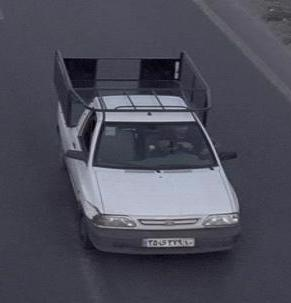

C:\Users\ASUS\Desktop\مکتب شریف\مکتب 145\پروژه دوم\data\train - merge - clean\vanet\217216852.jpg


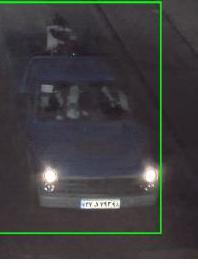

C:\Users\ASUS\Desktop\مکتب شریف\مکتب 145\پروژه دوم\data\train - merge - clean\vanet\214726285.jpg


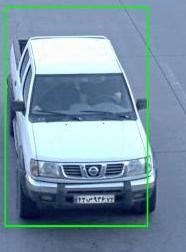

C:\Users\ASUS\Desktop\مکتب شریف\مکتب 145\پروژه دوم\data\train - merge - clean\vanet\217178596.jpg


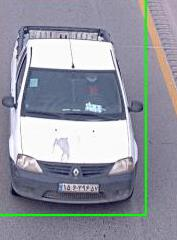

C:\Users\ASUS\Desktop\مکتب شریف\مکتب 145\پروژه دوم\data\train - merge - clean\vanet\216618067.jpg


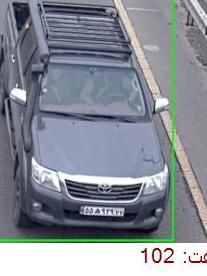

In [215]:
from PIL import Image
from IPython.display import display

for path in wrong_vanet_to_savari[:5]:

    image = Image.open(path).convert("RGB")
    image.thumbnail((400, 400))

    print(path)
    display(image)

In [216]:
from src.data_loader import VehicleDataset

In [217]:
from torchvision import transforms
from torch.utils.data import DataLoader

train_transform_aug = transforms.Compose([
    transforms.Resize((224, 224)),

    transforms.RandomHorizontalFlip(p=0.5),

    transforms.RandomRotation(40),

    transforms.RandomPerspective(
        distortion_scale=0.3,
        p=0.5
    ),

    transforms.ColorJitter(
        brightness=0.2,
        contrast=0.2,
        saturation=0.2,
        hue=0.05
    ),

    transforms.ToTensor()
])

val_transform_aug = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor()
])


train_dataset_aug = VehicleDataset(
    X_train,
    y_train,
    transform=train_transform_aug
)

val_dataset_aug = VehicleDataset(
    X_val,
    y_val,
    transform=val_transform_aug
)


train_loader_aug = DataLoader(
    train_dataset_aug,
    batch_size=32,
    shuffle=True,
    num_workers=0
)

val_loader_aug = DataLoader(
    val_dataset_aug,
    batch_size=32,
    shuffle=False,
    num_workers=0
)

print(train_loader_aug)
print(val_loader_aug)

In [218]:
from torchvision import models
import torch.nn as nn
import torch.optim as optim

resnet18_aug = models.resnet18(weights="DEFAULT")

resnet18_aug.fc = nn.Linear(
    resnet18_aug.fc.in_features,
    8
)

for param in resnet18_aug.parameters():
    param.requires_grad = False

for param in resnet18_aug.layer3.parameters():
    param.requires_grad = True

for param in resnet18_aug.layer4.parameters():
    param.requires_grad = True

for param in resnet18_aug.fc.parameters():
    param.requires_grad = True

resnet18_aug = resnet18_aug.to(device)

criterion_aug = nn.CrossEntropyLoss()

optimizer_aug = optim.Adam(
    filter(lambda p: p.requires_grad, resnet18_aug.parameters()),
    lr=2e-5
)

best_val_acc_aug = 0.0
best_state_aug = None

In [219]:
num_epochs = 15

for epoch in range(num_epochs):

    # =========================
    # Train
    # =========================
    resnet18_aug.train()

    train_loss = 0.0
    train_correct = 0
    train_total = 0

    for images, labels in train_loader_aug:

        images = images.to(device)
        labels = labels.to(device)

        optimizer_aug.zero_grad()

        outputs = resnet18_aug(images)

        loss = criterion_aug(outputs, labels)

        loss.backward()
        optimizer_aug.step()

        train_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)

        train_correct += (predictions == labels).sum().item()
        train_total += labels.size(0)

    train_loss /= train_total
    train_acc = train_correct / train_total


    # =========================
    # Validation
    # =========================
    resnet18_aug.eval()

    val_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for images, labels in val_loader_aug:

            images = images.to(device)
            labels = labels.to(device)

            outputs = resnet18_aug(images)

            loss = criterion_aug(outputs, labels)

            val_loss += loss.item() * images.size(0)

            predictions = outputs.argmax(dim=1)

            val_correct += (predictions == labels).sum().item()
            val_total += labels.size(0)

    val_loss /= val_total
    val_acc = val_correct / val_total


    # =========================
    # Save best weights
    # =========================
    if val_acc > best_val_acc_aug:

        best_val_acc_aug = val_acc

        best_state_aug = {
            key: value.cpu().clone()
            for key, value in resnet18_aug.state_dict().items()
        }

    print(
        f"Epoch {epoch+1}/{num_epochs} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.4f}"
    )

Epoch 1/15 | Train Loss: 1.7305 | Train Acc: 0.4203 | Val Loss: 1.4936 | Val Acc: 0.5169
Epoch 2/15 | Train Loss: 1.0379 | Train Acc: 0.7385 | Val Loss: 0.8850 | Val Acc: 0.7974
Epoch 3/15 | Train Loss: 0.7074 | Train Acc: 0.8360 | Val Loss: 0.6504 | Val Acc: 0.8416
Epoch 4/15 | Train Loss: 0.5122 | Train Acc: 0.8816 | Val Loss: 0.4896 | Val Acc: 0.8857
Epoch 5/15 | Train Loss: 0.4063 | Train Acc: 0.8979 | Val Loss: 0.4017 | Val Acc: 0.9169
Epoch 6/15 | Train Loss: 0.3281 | Train Acc: 0.9245 | Val Loss: 0.3545 | Val Acc: 0.9221
Epoch 7/15 | Train Loss: 0.2648 | Train Acc: 0.9447 | Val Loss: 0.2816 | Val Acc: 0.9325
Epoch 8/15 | Train Loss: 0.2277 | Train Acc: 0.9480 | Val Loss: 0.2525 | Val Acc: 0.9403
Epoch 9/15 | Train Loss: 0.1997 | Train Acc: 0.9525 | Val Loss: 0.2254 | Val Acc: 0.9429
Epoch 10/15 | Train Loss: 0.1637 | Train Acc: 0.9623 | Val Loss: 0.1974 | Val Acc: 0.9481
Epoch 11/15 | Train Loss: 0.1487 | Train Acc: 0.9668 | Val Loss: 0.2043 | Val Acc: 0.9455
Epoch 12/15 | Train

In [220]:
resnet18_aug.load_state_dict(best_state_aug)

print(f"Best Val Accuracy: {best_val_acc_aug:.4f}")

Best Val Accuracy: 0.9584


In [221]:
train_transform_norm_aug = transforms.Compose([
    transforms.Resize((224, 224)),

    transforms.RandomHorizontalFlip(p=0.5),

    transforms.RandomRotation(10),

    transforms.ColorJitter(
        brightness=0.2,
        contrast=0.2,
        saturation=0.2,
        hue=0.05
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

In [222]:
val_transform_norm_aug = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

In [223]:
print(type(train_loader.dataset))
print(type(val_loader.dataset))

<class 'src.data_loader.VehicleDataset'>
<class 'src.data_loader.VehicleDataset'>


In [224]:
train_dataset_norm_aug = VehicleDataset(
    image_paths=X_train,
    labels=y_train,
    transform=train_transform_norm_aug
)

val_dataset_norm_aug = VehicleDataset(
    image_paths=X_val,
    labels=y_val,
    transform=val_transform_norm_aug
)

In [225]:
from torch.utils.data import DataLoader

train_loader_norm_aug = DataLoader(
    train_dataset_norm_aug,
    batch_size=32,
    shuffle=True,
    num_workers=0
)

val_loader_norm_aug = DataLoader(
    val_dataset_norm_aug,
    batch_size=32,
    shuffle=False,
    num_workers=0
)

In [226]:
images, labels = next(iter(train_loader_norm_aug))

print("Images shape:", images.shape)
print("Labels shape:", labels.shape)
print("Min:", images.min().item())
print("Max:", images.max().item())

Images shape: torch.Size([32, 3, 224, 224])
Labels shape: torch.Size([32])
Min: -2.1179039478302
Max: 2.640000104904175


In [227]:
import torch
import torch.nn as nn
from torchvision import models

resnet18_norm_aug = models.resnet18(
    weights=models.ResNet18_Weights.DEFAULT
)

# Freeze همه لایه‌ها
for param in resnet18_norm_aug.parameters():
    param.requires_grad = False

# باز کردن layer3 و layer4
for param in resnet18_norm_aug.layer3.parameters():
    param.requires_grad = True

for param in resnet18_norm_aug.layer4.parameters():
    param.requires_grad = True

# تغییر classifier
resnet18_norm_aug.fc = nn.Linear(
    resnet18_norm_aug.fc.in_features,
    8
)

resnet18_norm_aug = resnet18_norm_aug.to(device)

In [228]:
for name, param in resnet18_norm_aug.named_parameters():
    if param.requires_grad:
        print(name)

layer3.0.conv1.weight
layer3.0.bn1.weight
layer3.0.bn1.bias
layer3.0.conv2.weight
layer3.0.bn2.weight
layer3.0.bn2.bias
layer3.0.downsample.0.weight
layer3.0.downsample.1.weight
layer3.0.downsample.1.bias
layer3.1.conv1.weight
layer3.1.bn1.weight
layer3.1.bn1.bias
layer3.1.conv2.weight
layer3.1.bn2.weight
layer3.1.bn2.bias
layer4.0.conv1.weight
layer4.0.bn1.weight
layer4.0.bn1.bias
layer4.0.conv2.weight
layer4.0.bn2.weight
layer4.0.bn2.bias
layer4.0.downsample.0.weight
layer4.0.downsample.1.weight
layer4.0.downsample.1.bias
layer4.1.conv1.weight
layer4.1.bn1.weight
layer4.1.bn1.bias
layer4.1.conv2.weight
layer4.1.bn2.weight
layer4.1.bn2.bias
fc.weight
fc.bias


In [229]:
criterion_norm_aug = nn.CrossEntropyLoss()

optimizer_norm_aug = torch.optim.Adam(
    filter(lambda p: p.requires_grad, resnet18_norm_aug.parameters()),
    lr=2e-5
)

In [230]:
num_epochs_norm_aug = 15

best_val_accuracy_norm_aug = 0.0

for epoch in range(num_epochs_norm_aug):

    # --------------------
    # Training
    # --------------------
    resnet18_norm_aug.train()

    train_loss = 0.0
    train_correct = 0
    train_total = 0

    for images, labels in train_loader_norm_aug:

        images = images.to(device)
        labels = labels.to(device)

        optimizer_norm_aug.zero_grad()

        outputs = resnet18_norm_aug(images)

        loss = criterion_norm_aug(outputs, labels)

        loss.backward()
        optimizer_norm_aug.step()

        train_loss += loss.item() * images.size(0)

        _, predicted = torch.max(outputs, 1)

        train_total += labels.size(0)
        train_correct += (predicted == labels).sum().item()

    train_loss /= train_total
    train_accuracy = 100 * train_correct / train_total

    # --------------------
    # Validation
    # --------------------
    resnet18_norm_aug.eval()

    val_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for images, labels in val_loader_norm_aug:

            images = images.to(device)
            labels = labels.to(device)

            outputs = resnet18_norm_aug(images)

            loss = criterion_norm_aug(outputs, labels)

            val_loss += loss.item() * images.size(0)

            _, predicted = torch.max(outputs, 1)

            val_total += labels.size(0)
            val_correct += (predicted == labels).sum().item()

    val_loss /= val_total
    val_accuracy = 100 * val_correct / val_total

    print(
        f"Epoch {epoch+1}/{num_epochs_norm_aug} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_accuracy:.2f}% | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_accuracy:.2f}%"
    )

    # --------------------
    # Save best model
    # --------------------
    if val_accuracy > best_val_accuracy_norm_aug:

        best_val_accuracy_norm_aug = val_accuracy

        torch.save(
            resnet18_norm_aug.state_dict(),
            "resnet18_layer3_layer4_norm_aug_best.pth"
        )

        print(
            f"  --> Best model saved: "
            f"{best_val_accuracy_norm_aug:.2f}%"
        )

Epoch 1/15 | Train Loss: 1.6940 | Train Acc: 38.91% | Val Loss: 1.1330 | Val Acc: 75.58%
  --> Best model saved: 75.58%
Epoch 2/15 | Train Loss: 0.9229 | Train Acc: 78.20% | Val Loss: 0.6627 | Val Acc: 86.23%
  --> Best model saved: 86.23%
Epoch 3/15 | Train Loss: 0.5705 | Train Acc: 90.24% | Val Loss: 0.4330 | Val Acc: 90.13%
  --> Best model saved: 90.13%
Epoch 4/15 | Train Loss: 0.3789 | Train Acc: 93.88% | Val Loss: 0.3436 | Val Acc: 92.21%
  --> Best model saved: 92.21%
Epoch 5/15 | Train Loss: 0.2868 | Train Acc: 94.47% | Val Loss: 0.2646 | Val Acc: 93.77%
  --> Best model saved: 93.77%
Epoch 6/15 | Train Loss: 0.2099 | Train Acc: 96.49% | Val Loss: 0.2194 | Val Acc: 94.55%
  --> Best model saved: 94.55%
Epoch 7/15 | Train Loss: 0.1768 | Train Acc: 97.01% | Val Loss: 0.1888 | Val Acc: 95.32%
  --> Best model saved: 95.32%
Epoch 8/15 | Train Loss: 0.1448 | Train Acc: 97.40% | Val Loss: 0.1628 | Val Acc: 96.62%
  --> Best model saved: 96.62%
Epoch 9/15 | Train Loss: 0.1192 | Train 

In [231]:
best_model_norm_aug = models.resnet18(
    weights=None
)

best_model_norm_aug.fc = nn.Linear(
    best_model_norm_aug.fc.in_features,
    8
)

best_model_norm_aug.load_state_dict(
    torch.load(
         "../models/resnet18_layer3_layer4_norm_aug_best.pth",
        map_location=device
    )
)

best_model_norm_aug = best_model_norm_aug.to(device)

print("Best validation accuracy:", best_val_accuracy_norm_aug)
print("Checkpoint loaded successfully.")

Best validation accuracy: 97.40259740259741
Checkpoint loaded successfully.


In [232]:
from sklearn.metrics import classification_report, confusion_matrix
import numpy as np
import torch

best_model_norm_aug.eval()

all_labels = []
all_predictions = []

with torch.no_grad():
    for images, labels in val_loader_norm_aug:
        images = images.to(device)

        outputs = best_model_norm_aug(images)
        predictions = outputs.argmax(dim=1).cpu().numpy()

        all_predictions.extend(predictions)
        all_labels.extend(labels.numpy())

print(classification_report(
    all_labels,
    all_predictions,
    digits=4,
    zero_division=0
))

print("Confusion Matrix:")
print(confusion_matrix(all_labels, all_predictions))

              precision    recall  f1-score   support

           0     1.0000    0.9767    0.9882        43
           1     0.9804    1.0000    0.9901        50
           2     0.9730    0.9000    0.9351        40
           3     0.9508    1.0000    0.9748        58
           4     0.9783    1.0000    0.9890        45
           5     0.9412    0.9600    0.9505        50
           6     0.9800    1.0000    0.9899        49
           7     0.9787    0.9200    0.9485        50

    accuracy                         0.9714       385
   macro avg     0.9728    0.9696    0.9708       385
weighted avg     0.9717    0.9714    0.9712       385

Confusion Matrix:
[[42  0  0  0  0  0  0  1]
 [ 0 50  0  0  0  0  0  0]
 [ 0  0 36  3  1  0  0  0]
 [ 0  0  0 58  0  0  0  0]
 [ 0  0  0  0 45  0  0  0]
 [ 0  1  0  0  0 48  1  0]
 [ 0  0  0  0  0  0 49  0]
 [ 0  0  1  0  0  3  0 46]]


In [233]:
# Final Validation - Confusion Matrices

from sklearn.metrics import confusion_matrix
import numpy as np

cm_counts = confusion_matrix(
    all_labels,
    all_predictions,
    labels=range(len(classes))
)

cm_normalized = confusion_matrix(
    all_labels,
    all_predictions,
    labels=range(len(classes)),
    normalize="true"
)

print("Count Confusion Matrix:")
print(cm_counts)

print("\nRow-Normalized Confusion Matrix:")
print(np.round(cm_normalized, 3))

Count Confusion Matrix:
[[42  0  0  0  0  0  0  1]
 [ 0 50  0  0  0  0  0  0]
 [ 0  0 36  3  1  0  0  0]
 [ 0  0  0 58  0  0  0  0]
 [ 0  0  0  0 45  0  0  0]
 [ 0  1  0  0  0 48  1  0]
 [ 0  0  0  0  0  0 49  0]
 [ 0  0  1  0  0  3  0 46]]

Row-Normalized Confusion Matrix:
[[0.977 0.    0.    0.    0.    0.    0.    0.023]
 [0.    1.    0.    0.    0.    0.    0.    0.   ]
 [0.    0.    0.9   0.075 0.025 0.    0.    0.   ]
 [0.    0.    0.    1.    0.    0.    0.    0.   ]
 [0.    0.    0.    0.    1.    0.    0.    0.   ]
 [0.    0.02  0.    0.    0.    0.96  0.02  0.   ]
 [0.    0.    0.    0.    0.    0.    1.    0.   ]
 [0.    0.    0.02  0.    0.    0.06  0.    0.92 ]]


In [234]:
import pandas as pd

print("Count Confusion Matrix:")
display(
    pd.DataFrame(
        cm_counts,
        index=classes,
        columns=classes
    )
)

print("\nRow-Normalized Confusion Matrix:")
display(
    pd.DataFrame(
        np.round(cm_normalized, 3),
        index=classes,
        columns=classes
    )
)

Count Confusion Matrix:


,ambulance,autobus,kamyun,kamyunet,minibus,savari,taxi,vanet
ambulance,42,0,0,0,0,0,0,1
autobus,0,50,0,0,0,0,0,0
kamyun,0,0,36,3,1,0,0,0
kamyunet,0,0,0,58,0,0,0,0
minibus,0,0,0,0,45,0,0,0
savari,0,1,0,0,0,48,1,0
taxi,0,0,0,0,0,0,49,0
vanet,0,0,1,0,0,3,0,46



Row-Normalized Confusion Matrix:


,ambulance,autobus,kamyun,kamyunet,minibus,savari,taxi,vanet
ambulance,0.977,0.00,0.00,0.000,0.000,0.00,0.00,0.023
autobus,0.000,1.00,0.00,0.000,0.000,0.00,0.00,0.000
kamyun,0.000,0.00,0.90,0.075,0.025,0.00,0.00,0.000
kamyunet,0.000,0.00,0.00,1.000,0.000,0.00,0.00,0.000
minibus,0.000,0.00,0.00,0.000,1.000,0.00,0.00,0.000
savari,0.000,0.02,0.00,0.000,0.000,0.96,0.02,0.000
taxi,0.000,0.00,0.00,0.000,0.000,0.00,1.00,0.000
vanet,0.000,0.00,0.02,0.000,0.000,0.06,0.00,0.920


In [235]:
# Validation confidence

best_model_norm_aug.eval()

all_labels_conf = []
all_predictions_conf = []
all_confidences = []

with torch.no_grad():

    for images, labels in val_loader_norm_aug:

        images = images.to(device)

        outputs = best_model_norm_aug(images)

        probabilities = torch.softmax(outputs, dim=1)

        confidences, predictions = probabilities.max(dim=1)

        all_labels_conf.extend(labels.numpy())
        all_predictions_conf.extend(predictions.cpu().numpy())
        all_confidences.extend(confidences.cpu().numpy())


all_labels_conf = np.array(all_labels_conf)
all_predictions_conf = np.array(all_predictions_conf)
all_confidences = np.array(all_confidences)

print("Validation samples:", len(all_labels_conf))
print("Mean confidence:", all_confidences.mean())

Validation samples: 385
Mean confidence: 0.9337832


In [236]:
# Get validation predictions and confidence

best_model_norm_aug.eval()

all_labels_conf = []
all_predictions_conf = []
all_confidences = []

with torch.no_grad():

    for images, labels in val_loader_norm_aug:

        images = images.to(device)

        outputs = best_model_norm_aug(images)

        probabilities = torch.softmax(outputs, dim=1)

        confidences, predictions = probabilities.max(dim=1)

        all_labels_conf.extend(labels.numpy())
        all_predictions_conf.extend(predictions.cpu().numpy())
        all_confidences.extend(confidences.cpu().numpy())

all_labels_conf = np.array(all_labels_conf)
all_predictions_conf = np.array(all_predictions_conf)
all_confidences = np.array(all_confidences)

print("Validation samples:", len(all_labels_conf))
print("Mean confidence:", round(all_confidences.mean(), 4))
print("Minimum confidence:", round(all_confidences.min(), 4))
print("Maximum confidence:", round(all_confidences.max(), 4))

Validation samples: 385
Mean confidence: 0.9338
Minimum confidence: 0.3165
Maximum confidence: 0.9997


In [237]:
# Compare different confidence thresholds

thresholds = [0.50, 0.60, 0.70, 0.80, 0.90]

threshold_results = []

total_errors = (
    all_predictions_conf != all_labels_conf
).sum()

for threshold in thresholds:

    needs_review = all_confidences < threshold
    accepted = ~needs_review

    review_count = needs_review.sum()
    accepted_count = accepted.sum()

    review_percentage = (
        review_count / len(all_labels_conf)
    ) * 100

    coverage = (
        accepted_count / len(all_labels_conf)
    ) * 100

    accepted_accuracy = (
        all_predictions_conf[accepted] ==
        all_labels_conf[accepted]
    ).mean() * 100

    errors_caught = (
        (
            (all_predictions_conf != all_labels_conf)
            & needs_review
        ).sum()
    )

    error_capture_rate = (
        errors_caught / total_errors
    ) * 100 if total_errors > 0 else 0

    threshold_results.append({
        "Threshold": threshold,
        "Review Count": review_count,
        "Review %": round(review_percentage, 2),
        "Coverage %": round(coverage, 2),
        "Accepted Accuracy %": round(accepted_accuracy, 2),
        "Errors Sent to Review": errors_caught,
        "Error Capture %": round(error_capture_rate, 2)
    })

threshold_df = pd.DataFrame(threshold_results)

display(threshold_df)

,Threshold,Review Count,Review %,Coverage %,Accepted Accuracy %,Errors Sent to Review,Error Capture %
0,0.5,8,2.08,97.92,98.14,4,36.36
1,0.6,18,4.68,95.32,99.18,8,72.73
2,0.7,29,7.53,92.47,99.72,10,90.91
3,0.8,45,11.69,88.31,100.00,11,100.00
4,0.9,68,17.66,82.34,100.00,11,100.00


In [238]:
selected_threshold = 0.70

print("Selected Threshold:", selected_threshold)

Selected Threshold: 0.7


In [239]:
needs_review = all_confidences < selected_threshold

print("Selected Threshold:", selected_threshold)
print("Review Count:", needs_review.sum())
print("Review Percentage:",
      round(100 * needs_review.mean(), 2), "%")
print("Accepted Count:", (~needs_review).sum())
print("Coverage:",
      round(100 * (~needs_review).mean(), 2), "%")

Selected Threshold: 0.7
Review Count: 29
Review Percentage: 7.53 %
Accepted Count: 356
Coverage: 92.47 %


In [240]:
# Misclassified Validation Samples

best_model_norm_aug.eval()

misclassified_samples = []

with torch.no_grad():

    for batch_idx, (images, labels) in enumerate(val_loader_norm_aug):

        images = images.to(device)

        outputs = best_model_norm_aug(images)

        probabilities = torch.softmax(outputs, dim=1)

        confidences, predictions = probabilities.max(dim=1)

        for i in range(len(labels)):

            true_label = labels[i].item()
            predicted_label = predictions[i].item()
            confidence = confidences[i].item()

            if true_label != predicted_label:

                global_index = batch_idx * val_loader_norm_aug.batch_size + i

                misclassified_samples.append({
                    "index": global_index,
                    "image_path": X_val[global_index],
                    "true_label": classes[true_label],
                    "prediction": classes[predicted_label],
                    "confidence": confidence
                })

print("Number of misclassified validation samples:",
      len(misclassified_samples))

Number of misclassified validation samples: 11


In [241]:
# Misclassified Samples Table

misclassified_df = pd.DataFrame(misclassified_samples)

misclassified_df["confidence"] = (
    misclassified_df["confidence"] * 100
).round(2)

display(misclassified_df)

,index,image_path,true_label,prediction,confidence
0,36,C:\Users\ASUS\Desktop\مکتب شریف\مکتب 145\پروژه...,kamyun,kamyunet,46.61
1,50,C:\Users\ASUS\Desktop\مکتب شریف\مکتب 145\پروژه...,savari,autobus,42.49
2,64,C:\Users\ASUS\Desktop\مکتب شریف\مکتب 145\پروژه...,vanet,savari,57.37
3,129,C:\Users\ASUS\Desktop\مکتب شریف\مکتب 145\پروژه...,kamyun,minibus,41.46
4,158,C:\Users\ASUS\Desktop\مکتب شریف\مکتب 145\پروژه...,kamyun,kamyunet,42.27
5,160,C:\Users\ASUS\Desktop\مکتب شریف\مکتب 145\پروژه...,savari,taxi,50.12
6,175,C:\Users\ASUS\Desktop\مکتب شریف\مکتب 145\پروژه...,ambulance,vanet,66.80
7,253,C:\Users\ASUS\Desktop\مکتب شریف\مکتب 145\پروژه...,vanet,savari,68.04
8,264,C:\Users\ASUS\Desktop\مکتب شریف\مکتب 145\پروژه...,vanet,savari,57.86
9,305,C:\Users\ASUS\Desktop\مکتب شریف\مکتب 145\پروژه...,kamyun,kamyunet,53.97


In [242]:
# Sort misclassified samples by confidence

misclassified_sorted = misclassified_df.sort_values(
    by="confidence",
    ascending=True
).reset_index(drop=True)

display(misclassified_sorted)

,index,image_path,true_label,prediction,confidence
0,129,C:\Users\ASUS\Desktop\مکتب شریف\مکتب 145\پروژه...,kamyun,minibus,41.46
1,158,C:\Users\ASUS\Desktop\مکتب شریف\مکتب 145\پروژه...,kamyun,kamyunet,42.27
2,50,C:\Users\ASUS\Desktop\مکتب شریف\مکتب 145\پروژه...,savari,autobus,42.49
3,36,C:\Users\ASUS\Desktop\مکتب شریف\مکتب 145\پروژه...,kamyun,kamyunet,46.61
4,160,C:\Users\ASUS\Desktop\مکتب شریف\مکتب 145\پروژه...,savari,taxi,50.12
5,305,C:\Users\ASUS\Desktop\مکتب شریف\مکتب 145\پروژه...,kamyun,kamyunet,53.97
6,64,C:\Users\ASUS\Desktop\مکتب شریف\مکتب 145\پروژه...,vanet,savari,57.37
7,264,C:\Users\ASUS\Desktop\مکتب شریف\مکتب 145\پروژه...,vanet,savari,57.86
8,175,C:\Users\ASUS\Desktop\مکتب شریف\مکتب 145\پروژه...,ambulance,vanet,66.80
9,253,C:\Users\ASUS\Desktop\مکتب شریف\مکتب 145\پروژه...,vanet,savari,68.04


In [ ]:
from PIL import Image
from IPython.display import display

# Show misclassified images

for _, row in misclassified_sorted.iterrows():

    image = Image.open(row["image_path"]).convert("RGB")

    print(
        f"True: {row['true_label']} | "
        f"Prediction: {row['prediction']} | "
        f"Confidence: {row['confidence']:.2f}%"
    )

    display(image)

    print("-" * 60)

In [244]:
# Apply selected threshold to misclassified samples

selected_threshold = 0.70

misclassified_sorted["needs_review"] = (
    misclassified_sorted["confidence"] / 100
    < selected_threshold
)

display(
    misclassified_sorted[
        [
            "index",
            "true_label",
            "prediction",
            "confidence",
            "needs_review"
        ]
    ]
)

,index,true_label,prediction,confidence,needs_review
0,129,kamyun,minibus,41.46,True
1,158,kamyun,kamyunet,42.27,True
2,50,savari,autobus,42.49,True
3,36,kamyun,kamyunet,46.61,True
4,160,savari,taxi,50.12,True
5,305,kamyun,kamyunet,53.97,True
6,64,vanet,savari,57.37,True
7,264,vanet,savari,57.86,True
8,175,ambulance,vanet,66.80,True
9,253,vanet,savari,68.04,True


In [245]:
pair_confusion_results = []

for i in range(len(classes)):
    for j in range(i + 1, len(classes)):

        score = (
            cm_normalized[i, j]
            + cm_normalized[j, i]
        )

        pair_confusion_results.append({
            "Class 1": classes[i],
            "Class 2": classes[j],
            "Pair Confusion %": round(score * 100, 2)
        })

pair_confusion_df = pd.DataFrame(pair_confusion_results)

pair_confusion_df = pair_confusion_df.sort_values(
    by="Pair Confusion %",
    ascending=False
).reset_index(drop=True)

display(pair_confusion_df)

,Class 1,Class 2,Pair Confusion %
0,kamyun,kamyunet,7.50
1,savari,vanet,6.00
2,kamyun,minibus,2.50
3,ambulance,vanet,2.33
4,kamyun,vanet,2.00
5,autobus,savari,2.00
6,savari,taxi,2.00
7,ambulance,taxi,0.00
8,ambulance,minibus,0.00
9,ambulance,kamyunet,0.00
